In [3]:
# FULL ANALYSIS — ALL EXPERIMENTS (COMPLETE)
# Reads from saved PKL and JSON files only
# No training, no inference, no GPU needed
# Saves to: experiments/full_analysis/
# Nothing overwritten anywhere
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT = OUT_ROOT / "experiments"
ANA_DIR  = EXP_ROOT / "full_analysis"
ANA_DIR.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    ANA_DIR / "01_froc_all_experiments.png",
    ANA_DIR / "02_froc_moderate.png",
    ANA_DIR / "03_froc_severe.png",
    ANA_DIR / "04_cpm_bar.png",
    ANA_DIR / "05_sensitivity_bar.png",
    ANA_DIR / "06_precision_bar.png",
    ANA_DIR / "07_fp_per_scan_bar.png",
    ANA_DIR / "08_per_client_fedavg_moderate.png",
    ANA_DIR / "09_per_client_fedprox_moderate.png",
    ANA_DIR / "10_per_client_fedavg_severe.png",
    ANA_DIR / "11_per_client_fedprox_severe_mu001.png",
    ANA_DIR / "12_per_client_fedprox_severe_mu010.png",
    ANA_DIR / "13_per_client_dp_fedavg_moderate.png",
    ANA_DIR / "14_per_client_comparison_moderate.png",
    ANA_DIR / "15_per_client_comparison_severe.png",
    ANA_DIR / "16_heterogeneity_cost.png",
    ANA_DIR / "17_mu_sensitivity.png",
    ANA_DIR / "18_privacy_cost.png",
    ANA_DIR / "19_fedprox_crossover.png",
    ANA_DIR / "20_froc_points_table.png",
    ANA_DIR / "21_resource_usage_training.png",
    ANA_DIR / "22_resource_usage_inference.png",
    ANA_DIR / "23_per_client_all_experiments_sensitivity.png",
    ANA_DIR / "24_per_client_all_experiments_precision.png",
    ANA_DIR / "25_per_client_all_experiments_fp_per_scan.png",
    ANA_DIR / "analysis_summary.json",
]
for f in files_that_would_be_written:
    assert not f.exists(), f"Would overwrite {f}"
print("✓ No existing files would be overwritten")
print(f"Output dir: {ANA_DIR}\n")

FP_PTS = [0.125, 0.25, 0.5, 1, 2, 4, 8]

# ── helpers ───────────────────────────────────────────────────
def compute_froc(scores, total_gt, n_scans):
    scores = sorted(scores, key=lambda x:x[0], reverse=True)
    sa = np.array([s[0] for s in scores])
    la = np.array([s[1] for s in scores])
    sl, fl = [], []
    for th in np.linspace(0.95, 0.01, 500):
        k = sa >= th
        sl.append(float(la[k].sum() / max(total_gt, 1)))
        fl.append(float((1-la[k]).sum() / max(n_scans, 1)))
    cpm_s = [sl[np.argmin([abs(f-fp) for f in fl])]
             for fp in FP_PTS]
    return sl, fl, cpm_s, float(np.mean(cpm_s))

def load_experiment(scores_path, results_path,
                    name, color, linestyle,
                    linewidth, group):
    sp = Path(scores_path)
    rp = Path(results_path)
    if not sp.exists() or not rp.exists():
        print(f"  ⚠  {name} — missing files")
        return None
    with open(sp,"rb") as f:
        scores = pickle.load(f)
    with open(rp) as f:
        res = json.load(f)
    tgt = res.get("total_gt", res.get("gt_nodules", 0))
    ns  = res.get("n_patients", 0)
    sl,fl,cpm_s,cpm = compute_froc(scores, tgt, ns)
    print(f"  ✓  {name:<42} CPM={cpm:.3f}  "
          f"Sens={res.get('sensitivity',0):.3f}  "
          f"Prec={res.get('precision',0):.3f}  "
          f"FP/scan={res.get('fp_per_scan',0):.2f}")
    return {
        "name"        : name,
        "sl"          : sl, "fl": fl,
        "cpm_s"       : cpm_s, "cpm": cpm,
        "sensitivity" : res.get("sensitivity", 0),
        "precision"   : res.get("precision", 0),
        "f1"          : res.get("f1", 0),
        "fp_per_scan" : res.get("fp_per_scan", 0),
        "total_gt"    : tgt, "n_patients": ns,
        "color"       : color,
        "linestyle"   : linestyle,
        "linewidth"   : linewidth,
        "group"       : group,
    }

def load_per_client(json_path):
    p = Path(json_path)
    if not p.exists():
        return None
    with open(p) as f:
        return json.load(f)

def load_resource(json_path):
    """Load resource usage from fl_history JSON."""
    p = Path(json_path)
    if not p.exists():
        return None
    with open(p) as f:
        return json.load(f)

def load_resource_png(png_path):
    """Check if resource PNG exists."""
    return Path(png_path).exists()

# ── load all experiments ──────────────────────────────────────
print("="*60)
print("LOADING ALL EXPERIMENTS")
print("="*60)

exps = {}

e = load_experiment(
    OUT_ROOT/"logs"/"all_scores.pkl",
    OUT_ROOT/"logs"/"client1_test_results_v3.json",
    "Client 1 local","black","--",1.5,"local")
if e: exps["c1_local"] = e

e = load_experiment(
    OUT_ROOT/"logs_global"/"global_all_scores.pkl",
    OUT_ROOT/"logs_global"/"global_test_results.json",
    "FedAvg moderate","steelblue","-",2.5,"moderate")
if e: exps["fedavg_mod"] = e

e = load_experiment(
    EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_scores.pkl",
    EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_test_results.json",
    "FedProx moderate (μ=0.01)","green","-",2.5,"moderate")
if e: exps["fedprox_mod"] = e

e = load_experiment(
    EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_scores.pkl",
    EXP_ROOT/"severe_noniid"/"fl_results"/"severe_test_results.json",
    "FedAvg severe","darkorange","-",2.5,"severe")
if e: exps["fedavg_sev"] = e

e = load_experiment(
    EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_scores.pkl",
    EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_test_results.json",
    "FedProx severe (μ=0.01)","mediumorchid","-",2.5,"severe")
if e: exps["fedprox_sev_mu001"] = e

e = load_experiment(
    EXP_ROOT/"fedprox_severe"/"fedprox_severe_scores.pkl",
    EXP_ROOT/"fedprox_severe"/"fedprox_severe_test_results.json",
    "FedProx severe (μ=0.10)","purple","--",2,"severe_mu")
if e: exps["fedprox_sev_mu010"] = e

e = load_experiment(
    EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_scores.pkl",
    EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_test_results.json",
    "DP-FedAvg moderate (ε≈5)","teal","-",2.5,"dp")
if e: exps["dp_fedavg_mod"] = e

print(f"\nLoaded {len(exps)} experiments\n")

# ── load per-client data ──────────────────────────────────────
print("="*60)
print("LOADING PER-CLIENT DATA")
print("="*60)

pc = {}
pc_paths = {
    "fedavg_mod"        : OUT_ROOT/"logs_global"/"per_client_metrics_fedavg_moderate.json",
    "fedprox_mod"       : EXP_ROOT/"fedprox_moderate"/"per_client_metrics_fedprox_moderate.json",
    "fedavg_sev"        : EXP_ROOT/"severe_noniid"/"fl_results"/"per_client_metrics_fedavg_severe.json",
    "fedprox_sev_mu001" : EXP_ROOT/"fedprox_severe_mu001"/"per_client_metrics_fedprox_severe_mu001.json",
    "fedprox_sev_mu010" : EXP_ROOT/"fedprox_severe"/"per_client_metrics_fedprox_severe.json",
    "dp_fedavg_mod"     : EXP_ROOT/"dp_fedavg_moderate_e5"/"per_client_metrics_dp_fedavg_moderate_e5.json",
}
for key, path in pc_paths.items():
    data = load_per_client(path)
    if data:
        pc[key] = data
        print(f"  ✓  {key}")
    else:
        print(f"  ⚠  {key} — not found")

client_descriptions = {
    "client1": "C1\nthin+small\nhigh_clean",
    "client2": "C2\nthin+large\nlow_clean",
    "client3": "C3\nmedium+any\nmid_clean",
    "client4": "C4\nthick+small\nhigh_clean",
    "client5": "C5\nthick+large\nlow_clean",
}
client_labels = [client_descriptions[f"client{i}"]
                 for i in range(1,6)]
client_keys   = [f"client{i}" for i in range(1,6)]

# ── load resource usage data ──────────────────────────────────
print("\n" + "="*60)
print("LOADING RESOURCE USAGE DATA")
print("="*60)

resource_configs = {
    "FedAvg moderate"        : {
        "history": OUT_ROOT/"logs_global"/"fl_history.json",
        "train_png": None,
        "infer_png": OUT_ROOT/"logs_global"/"resource_usage_inference.png",
    },
    "FedProx moderate"       : {
        "history": EXP_ROOT/"fedprox_moderate"/"fl_history_fedprox_moderate.json",
        "train_png": EXP_ROOT/"fedprox_moderate"/"resource_usage.png",
        "infer_png": EXP_ROOT/"fedprox_moderate"/"resource_usage_inference.png",
    },
    "FedAvg severe"          : {
        "history": EXP_ROOT/"severe_noniid"/"fl_results"/"fl_history_severe.json",
        "train_png": EXP_ROOT/"severe_noniid"/"fl_results"/"resource_usage_severe.png",
        "infer_png": EXP_ROOT/"severe_noniid"/"fl_results"/"resource_usage_inference.png",
    },
    "FedProx severe μ=0.01"  : {
        "history": EXP_ROOT/"fedprox_severe_mu001"/"fl_history_fedprox_severe_mu001.json",
        "train_png": EXP_ROOT/"fedprox_severe_mu001"/"resource_usage.png",
        "infer_png": EXP_ROOT/"fedprox_severe_mu001"/"resource_usage_inference.png",
    },
    "FedProx severe μ=0.10"  : {
        "history": EXP_ROOT/"fedprox_severe"/"fl_history_fedprox_severe.json",
        "train_png": EXP_ROOT/"fedprox_severe"/"resource_usage.png",
        "infer_png": EXP_ROOT/"fedprox_severe"/"resource_usage_inference.png",
    },
    "DP-FedAvg moderate ε≈5" : {
        "history": EXP_ROOT/"dp_fedavg_moderate_e5"/"fl_history_dp_fedavg_moderate_e5.json",
        "train_png": EXP_ROOT/"dp_fedavg_moderate_e5"/"resource_usage.png",
        "infer_png": EXP_ROOT/"dp_fedavg_moderate_e5"/"resource_usage_inference.png",
    },
}

resources = {}
for name, paths in resource_configs.items():
    hist = load_resource(paths["history"])
    resources[name] = {
        "history"   : hist,
        "train_png" : paths["train_png"],
        "infer_png" : paths["infer_png"],
    }
    status = "✓" if hist else "⚠"
    print(f"  {status}  {name}")

exp_order = ["c1_local","fedavg_mod","fedprox_mod",
             "fedavg_sev","fedprox_sev_mu001",
             "fedprox_sev_mu010","dp_fedavg_mod"]
exp_order = [k for k in exp_order if k in exps]

names  = [exps[k]["name"] for k in exp_order]
colors = [exps[k]["color"] for k in exp_order]
short_names = [
    n.replace("moderate","mod").replace("severe","sev")
     .replace("FedProx","FP").replace("FedAvg","FA")
     .replace("DP-FedAvg","DP-FA").replace(" (","(")
    for n in names]

# ── PLOT 1: FROC ALL ──────────────────────────────────────────
print("\n" + "="*60)
print("GENERATING PLOTS")
print("="*60)

fig, ax = plt.subplots(figsize=(12,8))
for key, exp in exps.items():
    ax.plot(exp["fl"], exp["sl"],
            color=exp["color"],
            linestyle=exp["linestyle"],
            linewidth=exp["linewidth"],
            label=f"{exp['name']}  CPM={exp['cpm']:.3f}")
    ax.scatter(FP_PTS, exp["cpm_s"],
               color=exp["color"], zorder=5, s=50)
ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5,
           label='Sens=0.9 target')
ax.set_xlabel('Average FP per scan',fontsize=13)
ax.set_ylabel('Sensitivity',fontsize=13)
ax.set_title('FROC Curves — All Experiments\n'
             'Federated Lung Nodule Detection on LIDC-IDRI',
             fontsize=14)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=9,loc='lower right')
ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(ANA_DIR/"01_froc_all_experiments.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  01_froc_all_experiments.png")

# ── PLOT 2: FROC MODERATE ────────────────────────────────────
fig, ax = plt.subplots(figsize=(10,7))
for key in ["c1_local","fedavg_mod","fedprox_mod",
            "dp_fedavg_mod"]:
    if key not in exps: continue
    exp = exps[key]
    ax.plot(exp["fl"],exp["sl"],
            color=exp["color"],linestyle=exp["linestyle"],
            linewidth=exp["linewidth"],
            label=f"{exp['name']}  CPM={exp['cpm']:.3f}")
    ax.scatter(FP_PTS,exp["cpm_s"],
               color=exp["color"],zorder=5,s=60)
ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5)
ax.set_xlabel('Average FP per scan',fontsize=12)
ax.set_ylabel('Sensitivity',fontsize=12)
ax.set_title('FROC — Moderate Non-IID\n'
             'FedAvg vs FedProx vs DP-FedAvg',fontsize=13)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=10); ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(ANA_DIR/"02_froc_moderate.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  02_froc_moderate.png")

# ── PLOT 3: FROC SEVERE ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(10,7))
for key in ["c1_local","fedavg_sev",
            "fedprox_sev_mu001","fedprox_sev_mu010"]:
    if key not in exps: continue
    exp = exps[key]
    ax.plot(exp["fl"],exp["sl"],
            color=exp["color"],linestyle=exp["linestyle"],
            linewidth=exp["linewidth"],
            label=f"{exp['name']}  CPM={exp['cpm']:.3f}")
    ax.scatter(FP_PTS,exp["cpm_s"],
               color=exp["color"],zorder=5,s=60)
ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5)
ax.set_xlabel('Average FP per scan',fontsize=12)
ax.set_ylabel('Sensitivity',fontsize=12)
ax.set_title('FROC — Severe Non-IID\n'
             'FedAvg vs FedProx μ=0.01 vs FedProx μ=0.10',
             fontsize=13)
ax.set_xlim(0,10); ax.set_ylim(0,1.05)
ax.legend(fontsize=10); ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(ANA_DIR/"03_froc_severe.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  03_froc_severe.png")

# ── PLOTS 4-7: METRIC BARS ────────────────────────────────────
for metric,ylabel,title,fname,ylim in [
    ("cpm","CPM","Competition Performance Metric (CPM)",
     "04_cpm_bar.png",(0,0.85)),
    ("sensitivity","Sensitivity","Sensitivity",
     "05_sensitivity_bar.png",(0,1.05)),
    ("precision","Precision","Precision",
     "06_precision_bar.png",(0,1.05)),
    ("fp_per_scan","FP per scan","False Positives per Scan",
     "07_fp_per_scan_bar.png",(0,5)),
]:
    vals = [exps[k][metric] for k in exp_order]
    x    = np.arange(len(exp_order))
    fig, ax = plt.subplots(figsize=(14,6))
    bars = ax.bar(x,vals,0.65,color=colors,alpha=0.85,
                  edgecolor='black',linewidth=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(short_names,fontsize=8,
                       rotation=15,ha='right')
    ax.set_ylabel(ylabel,fontsize=12)
    ax.set_title(title,fontsize=13)
    ax.set_ylim(ylim)
    ax.grid(True,alpha=0.3,axis='y')
    for b,v in zip(bars,vals):
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+ylim[1]*0.01,
                f'{v:.3f}',ha='center',va='bottom',
                fontsize=8,fontweight='bold')
    if metric=="cpm" and "c1_local" in exps:
        ax.axhline(exps["c1_local"]["cpm"],
                   color='black',linestyle='--',alpha=0.5,
                   label=f'C1 local={exps["c1_local"]["cpm"]:.3f}')
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(ANA_DIR/fname,dpi=150,bbox_inches='tight')
    plt.close()
    print(f"  ✓  {fname}")

# ── PLOTS 8-13: PER-CLIENT INDIVIDUAL ────────────────────────
def plot_per_client_single(pc_data, exp_name,
                            color, save_path):
    if pc_data is None: return
    summary = pc_data.get("per_client", pc_data)
    clients = sorted(summary.keys())
    sens  = [summary[c].get("sensitivity",0) for c in clients]
    precs = [summary[c].get("precision",0)   for c in clients]
    fps   = [summary[c].get("fp_per_scan",0) for c in clients]
    tps   = [summary[c].get("total_tp",0)    for c in clients]
    fps_n = [summary[c].get("total_fp",0)    for c in clients]
    fns   = [summary[c].get("total_fn",0)    for c in clients]
    gdata = pc_data.get("global",{})

    fig, axes = plt.subplots(2,3,figsize=(18,10))
    fig.suptitle(f"Per-Client Full Metrics\n{exp_name}",
                 fontsize=13)
    x = np.arange(len(clients))

    for ax, vals, label, g_key in [
        (axes[0,0], sens,  "Sensitivity", "sensitivity"),
        (axes[0,1], precs, "Precision",   "precision"),
        (axes[0,2], fps,   "FP/scan",     "fp_per_scan"),
    ]:
        g_val = gdata.get(g_key, 0)
        bars  = ax.bar(x,vals,0.6,color=color,alpha=0.85,
                       edgecolor='black',linewidth=0.5)
        ax.axhline(g_val,color='red',linestyle='--',
                   alpha=0.7,label=f'Global={g_val:.3f}')
        ax.set_xticks(x)
        ax.set_xticklabels(client_labels,fontsize=7)
        ax.set_ylabel(label,fontsize=10)
        ax.set_title(label,fontsize=11)
        ax.set_ylim(0,max(max(vals)*1.25,g_val*1.25,0.1))
        ax.legend(fontsize=8)
        ax.grid(True,alpha=0.3,axis='y')
        for b,v in zip(bars,vals):
            ax.text(b.get_x()+b.get_width()/2,
                    b.get_height()+0.01,f'{v:.3f}',
                    ha='center',va='bottom',fontsize=8)

    # TP FP FN counts
    for ax, vals, label, clr in [
        (axes[1,0], tps,  "Total TP", color),
        (axes[1,1], fps_n,"Total FP", "tomato"),
        (axes[1,2], fns,  "Total FN", "salmon"),
    ]:
        bars = ax.bar(x,vals,0.6,color=clr,alpha=0.85,
                      edgecolor='black',linewidth=0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(client_labels,fontsize=7)
        ax.set_ylabel("Count",fontsize=10)
        ax.set_title(label,fontsize=11)
        ax.grid(True,alpha=0.3,axis='y')
        for b,v in zip(bars,vals):
            ax.text(b.get_x()+b.get_width()/2,
                    b.get_height()+0.3,f'{v}',
                    ha='center',va='bottom',fontsize=9)

    plt.tight_layout()
    plt.savefig(save_path,dpi=150,bbox_inches='tight')
    plt.close()

pc_single_configs = [
    ("fedavg_mod",        "FedAvg Moderate",
     "steelblue",    "08_per_client_fedavg_moderate.png"),
    ("fedprox_mod",       "FedProx Moderate (μ=0.01)",
     "green",         "09_per_client_fedprox_moderate.png"),
    ("fedavg_sev",        "FedAvg Severe",
     "darkorange",    "10_per_client_fedavg_severe.png"),
    ("fedprox_sev_mu001", "FedProx Severe (μ=0.01)",
     "mediumorchid",  "11_per_client_fedprox_severe_mu001.png"),
    ("fedprox_sev_mu010", "FedProx Severe (μ=0.10)",
     "purple",        "12_per_client_fedprox_severe_mu010.png"),
    ("dp_fedavg_mod",     "DP-FedAvg Moderate (ε≈5)",
     "teal",          "13_per_client_dp_fedavg_moderate.png"),
]
for key,name,color,fname in pc_single_configs:
    plot_per_client_single(pc.get(key),name,
                           color,ANA_DIR/fname)
    print(f"  ✓  {fname}")

# ── PLOT 14: PER-CLIENT COMPARISON MODERATE ──────────────────
fig, axes = plt.subplots(1,3,figsize=(18,6))
fig.suptitle("Per-Client Comparison — Moderate Non-IID\n"
             "FedAvg vs FedProx (μ=0.01) vs DP-FedAvg (ε≈5)",
             fontsize=13)
mod_pc_keys   = ["fedavg_mod","fedprox_mod","dp_fedavg_mod"]
mod_pc_labels = ["FedAvg","FedProx\nμ=0.01","DP-FedAvg\nε≈5"]
mod_pc_colors = ["steelblue","green","teal"]
x = np.arange(5); w = 0.25; offsets = [-w,0,w]
for ax,metric,ylabel in [
    (axes[0],"sensitivity","Sensitivity"),
    (axes[1],"precision",  "Precision"),
    (axes[2],"fp_per_scan","FP per scan"),
]:
    for i,(key,label,color) in enumerate(
            zip(mod_pc_keys,mod_pc_labels,mod_pc_colors)):
        if key not in pc: continue
        summary = pc[key].get("per_client",pc[key])
        vals = [summary.get(f"client{j+1}",{}).get(metric,0)
                for j in range(5)]
        ax.bar(x+offsets[i],vals,w,label=label,
               color=color,alpha=0.85,
               edgecolor='black',linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(client_labels,fontsize=7)
    ax.set_ylabel(ylabel,fontsize=11)
    ax.set_title(ylabel,fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True,alpha=0.3,axis='y')
plt.tight_layout()
plt.savefig(ANA_DIR/"14_per_client_comparison_moderate.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  14_per_client_comparison_moderate.png")

# ── PLOT 15: PER-CLIENT COMPARISON SEVERE ────────────────────
fig, axes = plt.subplots(1,3,figsize=(18,6))
fig.suptitle("Per-Client Comparison — Severe Non-IID\n"
             "FedAvg vs FedProx μ=0.01 vs FedProx μ=0.10",
             fontsize=13)
sev_pc_keys   = ["fedavg_sev","fedprox_sev_mu001",
                 "fedprox_sev_mu010"]
sev_pc_labels = ["FedAvg","FedProx\nμ=0.01","FedProx\nμ=0.10"]
sev_pc_colors = ["darkorange","mediumorchid","purple"]
x = np.arange(5); w = 0.25; offsets = [-w,0,w]
for ax,metric,ylabel in [
    (axes[0],"sensitivity","Sensitivity"),
    (axes[1],"precision",  "Precision"),
    (axes[2],"fp_per_scan","FP per scan"),
]:
    for i,(key,label,color) in enumerate(
            zip(sev_pc_keys,sev_pc_labels,sev_pc_colors)):
        if key not in pc: continue
        summary = pc[key].get("per_client",pc[key])
        vals = [summary.get(f"client{j+1}",{}).get(metric,0)
                for j in range(5)]
        ax.bar(x+offsets[i],vals,w,label=label,
               color=color,alpha=0.85,
               edgecolor='black',linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(client_labels,fontsize=7)
    ax.set_ylabel(ylabel,fontsize=11)
    ax.set_title(ylabel,fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True,alpha=0.3,axis='y')
plt.tight_layout()
plt.savefig(ANA_DIR/"15_per_client_comparison_severe.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  15_per_client_comparison_severe.png")

# ── PLOT 16: HETEROGENEITY COST ───────────────────────────────
if "fedavg_mod" in exps and "fedavg_sev" in exps:
    fig, axes = plt.subplots(1,2,figsize=(14,6))
    fig.suptitle("Heterogeneity Cost\n"
                 "FedAvg: Moderate vs Severe Non-IID",
                 fontsize=13)
    ax = axes[0]
    for key,label in [("fedavg_mod","FedAvg Moderate"),
                       ("fedavg_sev","FedAvg Severe")]:
        exp = exps[key]
        ax.plot(exp["fl"],exp["sl"],color=exp["color"],
                linewidth=2.5,
                label=f"{label}  CPM={exp['cpm']:.3f}")
        ax.scatter(FP_PTS,exp["cpm_s"],
                   color=exp["color"],zorder=5,s=60)
    fp_c = np.linspace(0,10,300)
    sl_mi = np.interp(fp_c,exps["fedavg_mod"]["fl"],
                      exps["fedavg_mod"]["sl"])
    sl_si = np.interp(fp_c,exps["fedavg_sev"]["fl"],
                      exps["fedavg_sev"]["sl"])
    ax.fill_between(fp_c,sl_si,sl_mi,alpha=0.15,
                    color='red',label='Heterogeneity cost')
    ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5)
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title('FROC Comparison',fontsize=11)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
    ax = axes[1]
    x = np.arange(len(FP_PTS)); w = 0.35
    ax.bar(x-w/2,exps["fedavg_mod"]["cpm_s"],w,
           label=f'Moderate (CPM={exps["fedavg_mod"]["cpm"]:.3f})',
           color='steelblue',alpha=0.85)
    ax.bar(x+w/2,exps["fedavg_sev"]["cpm_s"],w,
           label=f'Severe (CPM={exps["fedavg_sev"]["cpm"]:.3f})',
           color='darkorange',alpha=0.85)
    drop = ((exps["fedavg_mod"]["cpm"] -
             exps["fedavg_sev"]["cpm"]) /
            exps["fedavg_mod"]["cpm"]*100)
    ax.set_xticks(x)
    ax.set_xticklabels([str(f) for f in FP_PTS],fontsize=9)
    ax.set_xlabel('FP per scan threshold',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title(f'Sensitivity at each FP point\n'
                 f'CPM drop: {drop:.1f}%',fontsize=11)
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    ax.set_ylim(0,1.1)
    plt.tight_layout()
    plt.savefig(ANA_DIR/"16_heterogeneity_cost.png",
                dpi=150,bbox_inches='tight')
    plt.close()
    print("  ✓  16_heterogeneity_cost.png")

# ── PLOT 17: μ SENSITIVITY ────────────────────────────────────
if all(k in exps for k in ["fedavg_sev",
       "fedprox_sev_mu001","fedprox_sev_mu010"]):
    fig, axes = plt.subplots(1,2,figsize=(14,6))
    fig.suptitle("FedProx μ Sensitivity — Severe Non-IID",
                 fontsize=13)
    ax = axes[0]
    for key in ["fedavg_sev","fedprox_sev_mu001",
                "fedprox_sev_mu010"]:
        exp = exps[key]
        ax.plot(exp["fl"],exp["sl"],color=exp["color"],
                linestyle=exp["linestyle"],
                linewidth=exp["linewidth"],
                label=f"{exp['name']}  CPM={exp['cpm']:.3f}")
        ax.scatter(FP_PTS,exp["cpm_s"],
                   color=exp["color"],zorder=5,s=60)
    ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5)
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title('FROC — μ Sensitivity',fontsize=11)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
    ax = axes[1]
    methods = ["FedAvg\n(no μ)","FedProx\nμ=0.01",
               "FedProx\nμ=0.10"]
    cpms    = [exps["fedavg_sev"]["cpm"],
               exps["fedprox_sev_mu001"]["cpm"],
               exps["fedprox_sev_mu010"]["cpm"]]
    clrs    = ["darkorange","mediumorchid","purple"]
    x = np.arange(3)
    bars = ax.bar(x,cpms,0.5,color=clrs,alpha=0.85,
                  edgecolor='black',linewidth=0.5)
    ax.set_xticks(x); ax.set_xticklabels(methods,fontsize=10)
    ax.set_ylabel('CPM',fontsize=12)
    ax.set_title('CPM vs μ Value\nSevere Non-IID',fontsize=11)
    ax.set_ylim(0,0.85); ax.grid(True,alpha=0.3,axis='y')
    for b,v in zip(bars,cpms):
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.01,f'{v:.3f}',
                ha='center',va='bottom',
                fontsize=10,fontweight='bold')
    plt.tight_layout()
    plt.savefig(ANA_DIR/"17_mu_sensitivity.png",
                dpi=150,bbox_inches='tight')
    plt.close()
    print("  ✓  17_mu_sensitivity.png")

# ── PLOT 18: PRIVACY COST ─────────────────────────────────────
if "fedavg_mod" in exps and "dp_fedavg_mod" in exps:
    fig, axes = plt.subplots(1,2,figsize=(14,6))
    fig.suptitle("Privacy-Utility Tradeoff\n"
                 "FedAvg vs DP-FedAvg (ε≈5) — Moderate Non-IID",
                 fontsize=13)
    ax = axes[0]
    for key in ["fedavg_mod","dp_fedavg_mod"]:
        exp = exps[key]
        ax.plot(exp["fl"],exp["sl"],color=exp["color"],
                linewidth=2.5,
                label=f"{exp['name']}  CPM={exp['cpm']:.3f}")
        ax.scatter(FP_PTS,exp["cpm_s"],
                   color=exp["color"],zorder=5,s=60)
    fp_c = np.linspace(0,10,300)
    sl_fai = np.interp(fp_c,exps["fedavg_mod"]["fl"],
                       exps["fedavg_mod"]["sl"])
    sl_dpi = np.interp(fp_c,exps["dp_fedavg_mod"]["fl"],
                       exps["dp_fedavg_mod"]["sl"])
    ax.fill_between(fp_c,sl_dpi,sl_fai,alpha=0.15,
                    color='orange',label='Privacy cost')
    ax.axhline(0.9,color='gray',linestyle=':',alpha=0.5)
    ax.set_xlabel('FP per scan',fontsize=12)
    ax.set_ylabel('Sensitivity',fontsize=12)
    ax.set_title('FROC Comparison',fontsize=11)
    ax.set_xlim(0,10); ax.set_ylim(0,1.05)
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
    ax = axes[1]
    metrics = ['CPM','Sensitivity','Precision','FP/scan']
    fa_vals = [exps["fedavg_mod"]["cpm"],
               exps["fedavg_mod"]["sensitivity"],
               exps["fedavg_mod"]["precision"],
               exps["fedavg_mod"]["fp_per_scan"]]
    dp_vals = [exps["dp_fedavg_mod"]["cpm"],
               exps["dp_fedavg_mod"]["sensitivity"],
               exps["dp_fedavg_mod"]["precision"],
               exps["dp_fedavg_mod"]["fp_per_scan"]]
    x = np.arange(4); w = 0.35
    ax.bar(x-w/2,fa_vals,w,label='FedAvg (no DP)',
           color='steelblue',alpha=0.85)
    ax.bar(x+w/2,dp_vals,w,label='DP-FedAvg (ε≈5)',
           color='teal',alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(metrics,fontsize=10)
    ax.set_ylabel('Score',fontsize=12)
    ax.set_title('Metric Comparison',fontsize=11)
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3,axis='y')
    cpm_cost = ((exps["fedavg_mod"]["cpm"] -
                 exps["dp_fedavg_mod"]["cpm"]) /
                exps["fedavg_mod"]["cpm"]*100)
    ax.set_xlabel(f'CPM cost of DP: {cpm_cost:.1f}%',
                  fontsize=10)
    for i,(fa,dp) in enumerate(zip(fa_vals,dp_vals)):
        ax.text(i-w/2,fa+0.01,f'{fa:.3f}',
                ha='center',va='bottom',fontsize=8)
        ax.text(i+w/2,dp+0.01,f'{dp:.3f}',
                ha='center',va='bottom',fontsize=8)
    plt.tight_layout()
    plt.savefig(ANA_DIR/"18_privacy_cost.png",
                dpi=150,bbox_inches='tight')
    plt.close()
    print("  ✓  18_privacy_cost.png")

# ── PLOT 19: FEDPROX CROSSOVER ────────────────────────────────
if all(k in exps for k in ["fedavg_mod","fedprox_mod",
                             "fedavg_sev","fedprox_sev_mu001"]):
    fig, ax = plt.subplots(figsize=(10,7))
    categories   = ['Moderate Non-IID','Severe Non-IID']
    fedavg_cpms  = [exps["fedavg_mod"]["cpm"],
                    exps["fedavg_sev"]["cpm"]]
    fedprox_cpms = [exps["fedprox_mod"]["cpm"],
                    exps["fedprox_sev_mu001"]["cpm"]]
    x = np.arange(2)
    ax.plot(x,fedavg_cpms,'o-',color='steelblue',
            linewidth=2.5,markersize=12,label='FedAvg')
    ax.plot(x,fedprox_cpms,'s--',color='mediumorchid',
            linewidth=2.5,markersize=12,
            label='FedProx (μ=0.01)')
    for i,(fa,fp) in enumerate(zip(fedavg_cpms,fedprox_cpms)):
        ax.annotate(f'{fa:.3f}',(i,fa),
                    textcoords="offset points",
                    xytext=(15,5),fontsize=11,
                    color='steelblue',fontweight='bold')
        ax.annotate(f'{fp:.3f}',(i,fp),
                    textcoords="offset points",
                    xytext=(15,-15),fontsize=11,
                    color='mediumorchid',fontweight='bold')
    ax.axvspan(0.4,0.6,alpha=0.1,color='red',
               label='Crossover region')
    diff_mod = ((fedavg_cpms[0]-fedprox_cpms[0]) /
                fedavg_cpms[0]*100)
    diff_sev = ((fedprox_cpms[1]-fedavg_cpms[1]) /
                fedavg_cpms[1]*100)
    ax.set_xticks(x)
    ax.set_xticklabels(categories,fontsize=12)
    ax.set_ylabel('CPM',fontsize=12)
    ax.set_title(
        'FedProx Crossover Behavior\n'
        f'Moderate: FedAvg better by {diff_mod:.1f}%  |  '
        f'Severe: FedProx better by {diff_sev:.1f}%',
        fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True,alpha=0.3)
    ax.set_ylim(0.5,0.85)
    plt.tight_layout()
    plt.savefig(ANA_DIR/"19_fedprox_crossover.png",
                dpi=150,bbox_inches='tight')
    plt.close()
    print("  ✓  19_fedprox_crossover.png")

# ── PLOT 20: FROC POINTS TABLE ────────────────────────────────
fig, ax = plt.subplots(figsize=(16,5))
ax.axis('off')
rows = []
for key in exp_order:
    if key not in exps: continue
    exp = exps[key]
    row = ([exp["name"]] +
           [f"{v:.3f}" for v in exp["cpm_s"]] +
           [f"{exp['cpm']:.3f}"])
    rows.append(row)
col_labels = (["Method"] +
              [f"FP={fp}" for fp in FP_PTS] +
              ["CPM"])
table = ax.table(cellText=rows,colLabels=col_labels,
                 loc='center',cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.2,1.8)
for j in range(len(col_labels)):
    table[0,j].set_facecolor('#2c3e50')
    table[0,j].set_text_props(color='white',
                               fontweight='bold')
for i in range(1,len(rows)+1):
    for j in range(len(col_labels)):
        if i%2==0:
            table[i,j].set_facecolor('#f8f9fa')
ax.set_title('Sensitivity at Each FROC Operating Point',
             fontsize=13,pad=20)
plt.tight_layout()
plt.savefig(ANA_DIR/"20_froc_points_table.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  20_froc_points_table.png")

# ── PLOT 21: RESOURCE USAGE — TRAINING (FL LOSS CURVES) ──────
print("PLOT 21: RESOURCE USAGE — TRAINING LOSS CURVES")

fl_history_paths = {
    "FedAvg moderate"       :
        OUT_ROOT/"logs_global"/"fl_history.json",
    "FedProx moderate"      :
        EXP_ROOT/"fedprox_moderate"/"fl_history_fedprox_moderate.json",
    "FedAvg severe"         :
        EXP_ROOT/"severe_noniid"/"fl_results"/"fl_history_severe.json",
    "FedProx severe μ=0.01" :
        EXP_ROOT/"fedprox_severe_mu001"/"fl_history_fedprox_severe_mu001.json",
    "FedProx severe μ=0.10" :
        EXP_ROOT/"fedprox_severe"/"fl_history_fedprox_severe.json",
    "DP-FedAvg moderate ε≈5":
        EXP_ROOT/"dp_fedavg_moderate_e5"/"fl_history_dp_fedavg_moderate_e5.json",
}
fl_colors = {
    "FedAvg moderate"       : "steelblue",
    "FedProx moderate"      : "green",
    "FedAvg severe"         : "darkorange",
    "FedProx severe μ=0.01" : "mediumorchid",
    "FedProx severe μ=0.10" : "purple",
    "DP-FedAvg moderate ε≈5": "teal",
}

fig, axes = plt.subplots(2,3,figsize=(18,10))
fig.suptitle("FL Training Loss per Round — All Experiments",
             fontsize=14)
axes_flat = axes.flatten()

for idx, (name, path) in enumerate(
        fl_history_paths.items()):
    ax = axes_flat[idx]
    p  = Path(path)
    if not p.exists():
        ax.text(0.5,0.5,"No data",
                ha='center',va='center',
                transform=ax.transAxes,fontsize=12)
        ax.set_title(name,fontsize=10)
        continue
    with open(p) as f:
        hist = json.load(f)
    losses = hist.get("losses_distributed",[])
    if not losses:
        ax.text(0.5,0.5,"No loss data",
                ha='center',va='center',
                transform=ax.transAxes,fontsize=12)
        ax.set_title(name,fontsize=10)
        continue
    rounds = [r for r,l in losses]
    lvals  = [l for r,l in losses]
    color  = fl_colors.get(name,"gray")
    ax.plot(rounds,lvals,'o-',color=color,
            linewidth=2,markersize=8)
    ax.set_xlabel('FL Round',fontsize=10)
    ax.set_ylabel('Distributed Loss',fontsize=10)
    ax.set_title(name,fontsize=10)
    ax.grid(True,alpha=0.3)
    for r,l in zip(rounds,lvals):
        ax.annotate(f'{l:.4f}',(r,l),
                    textcoords="offset points",
                    xytext=(0,8),fontsize=7,
                    ha='center',color=color)
    mu = hist.get("proximal_mu")
    nm = hist.get("noise_multiplier")
    ep = hist.get("privacy_epsilon")
    info = ""
    if mu is not None:   info += f"μ={mu}  "
    if nm is not None:   info += f"noise={nm}  "
    if ep is not None:   info += f"ε{ep}  "
    if info:
        ax.set_xlabel(f'FL Round  |  {info.strip()}',
                      fontsize=9)

plt.tight_layout()
plt.savefig(ANA_DIR/"21_resource_usage_training.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  21_resource_usage_training.png")

# ── PLOT 22: RESOURCE USAGE — RAM/VRAM FROM SAVED PNGS ───────
print("PLOT 22: RESOURCE USAGE — RAM/VRAM AVAILABILITY")

resource_png_paths = {
    "FedAvg moderate\n(training)"        :
        OUT_ROOT/"logs_global"/"resource_usage_inference.png",
    "FedProx moderate\n(training)"       :
        EXP_ROOT/"fedprox_moderate"/"resource_usage.png",
    "FedAvg severe\n(training)"          :
        EXP_ROOT/"severe_noniid"/"fl_results"/"resource_usage_severe.png",
    "FedProx severe μ=0.01\n(training)"  :
        EXP_ROOT/"fedprox_severe_mu001"/"resource_usage.png",
    "FedProx severe μ=0.10\n(training)"  :
        EXP_ROOT/"fedprox_severe"/"resource_usage.png",
    "DP-FedAvg moderate\n(training)"     :
        EXP_ROOT/"dp_fedavg_moderate_e5"/"resource_usage.png",
    "FedAvg moderate\n(inference)"       :
        OUT_ROOT/"logs_global"/"resource_usage_inference.png",
    "FedProx moderate\n(inference)"      :
        EXP_ROOT/"fedprox_moderate"/"resource_usage_inference.png",
    "FedAvg severe\n(inference)"         :
        EXP_ROOT/"severe_noniid"/"fl_results"/"resource_usage_inference.png",
    "FedProx severe μ=0.01\n(inference)" :
        EXP_ROOT/"fedprox_severe_mu001"/"resource_usage_inference.png",
    "FedProx severe μ=0.10\n(inference)" :
        EXP_ROOT/"fedprox_severe"/"resource_usage_inference.png",
    "DP-FedAvg moderate\n(inference)"    :
        EXP_ROOT/"dp_fedavg_moderate_e5"/"resource_usage_inference.png",
}

# create a summary table of which resource files exist
fig, ax = plt.subplots(figsize=(14,6))
ax.axis('off')

resource_rows = []
for label, path in resource_png_paths.items():
    exists = Path(path).exists()
    resource_rows.append([
        label.replace("\n"," "),
        "✓ Available" if exists else "⚠ Not found",
        str(path.name) if exists else "—",
    ])

rtable = ax.table(
    cellText=resource_rows,
    colLabels=["Experiment","Status","File"],
    loc='center',cellLoc='left'
)
rtable.auto_set_font_size(False)
rtable.set_fontsize(8)
rtable.scale(1.2,1.6)
for j in range(3):
    rtable[0,j].set_facecolor('#2c3e50')
    rtable[0,j].set_text_props(color='white',
                                fontweight='bold')
for i in range(1,len(resource_rows)+1):
    status = resource_rows[i-1][1]
    clr = '#d4edda' if '✓' in status else '#f8d7da'
    for j in range(3):
        rtable[i,j].set_facecolor(clr)

ax.set_title('Resource Usage Files (RAM/VRAM plots)\n'
             'Open individual PNG files for detailed plots',
             fontsize=12,pad=20)
plt.tight_layout()
plt.savefig(ANA_DIR/"22_resource_usage_inference.png",
            dpi=150,bbox_inches='tight')
plt.close()
print("  ✓  22_resource_usage_inference.png")
print("     Note: individual RAM/VRAM plots saved in")
print("     each experiment folder as resource_usage*.png")

# ── PLOTS 23-25: PER-CLIENT ALL EXPERIMENTS ──────────────────
print("PLOTS 23-25: PER-CLIENT ALL EXPERIMENTS COMPARISON")

all_pc_configs = [
    ("fedavg_mod",        "FedAvg\nModerate",    "steelblue"),
    ("fedprox_mod",       "FedProx\nMod μ=0.01", "green"),
    ("dp_fedavg_mod",     "DP-FedAvg\nMod ε≈5",  "teal"),
    ("fedavg_sev",        "FedAvg\nSevere",       "darkorange"),
    ("fedprox_sev_mu001", "FedProx\nSev μ=0.01",  "mediumorchid"),
    ("fedprox_sev_mu010", "FedProx\nSev μ=0.10",  "purple"),
]
available_pc = [(k,l,c) for k,l,c in all_pc_configs
                if k in pc]

for metric, ylabel, fname_num, fname in [
    ("sensitivity","Sensitivity","23",
     "23_per_client_all_experiments_sensitivity.png"),
    ("precision",  "Precision",  "24",
     "24_per_client_all_experiments_precision.png"),
    ("fp_per_scan","FP per scan","25",
     "25_per_client_all_experiments_fp_per_scan.png"),
]:
    n_exp = len(available_pc)
    if n_exp == 0:
        continue
    w     = 0.8 / n_exp
    x     = np.arange(5)
    offsets = np.linspace(-(n_exp-1)/2*w,
                           (n_exp-1)/2*w, n_exp)

    fig, ax = plt.subplots(figsize=(16,7))
    ax.set_title(
        f'Per-Client {ylabel} — All Experiments\n'
        f'Moderate (left 3) vs Severe (right 3)',
        fontsize=13)

    for i,(key,label,color) in enumerate(available_pc):
        summary = pc[key].get("per_client",pc[key])
        vals = [summary.get(f"client{j+1}",{}).get(metric,0)
                for j in range(5)]
        bars = ax.bar(x+offsets[i],vals,w*0.9,
                      label=label,color=color,
                      alpha=0.85,edgecolor='black',
                      linewidth=0.3)

    ax.set_xticks(x)
    ax.set_xticklabels(client_labels,fontsize=8)
    ax.set_ylabel(ylabel,fontsize=12)
    ax.legend(fontsize=8,loc='upper right',
              ncol=3,bbox_to_anchor=(1,1))
    ax.grid(True,alpha=0.3,axis='y')
    # add client description annotations
    desc_mod = ["thin+small\nhigh_clean",
                "thin+large\nlow_clean",
                "medium+any\nmid_clean",
                "thick+small\nhigh_clean",
                "thick+large\nlow_clean"]
    for xi,desc in enumerate(desc_mod):
        ax.text(xi,-0.18,desc,ha='center',
                va='top',fontsize=6,
                transform=ax.get_xaxis_transform(),
                color='gray')
    plt.tight_layout()
    plt.savefig(ANA_DIR/fname,dpi=150,bbox_inches='tight')
    plt.close()
    print(f"  ✓  {fname}")

# ── SUMMARY JSON ─────────────────────────────────────────────
print("\n" + "="*60)
print("SAVING SUMMARY JSON")
print("="*60)

summary = {}
for key, exp in exps.items():
    pc_data = pc.get(key,{})
    pc_summary = pc_data.get("per_client",{}) if pc_data else {}
    summary[key] = {
        "name"        : exp["name"],
        "group"       : exp["group"],
        "cpm"         : round(exp["cpm"],4),
        "sensitivity" : exp["sensitivity"],
        "precision"   : exp["precision"],
        "f1"          : exp["f1"],
        "fp_per_scan" : exp["fp_per_scan"],
        "n_patients"  : exp["n_patients"],
        "total_gt"    : exp["total_gt"],
        "cpm_at_fp_pts": {
            str(fp): round(s,4)
            for fp,s in zip(FP_PTS, exp["cpm_s"])
        },
        "per_client"  : {
            cid: {
                "sensitivity": v.get("sensitivity",0),
                "precision"  : v.get("precision",0),
                "fp_per_scan": v.get("fp_per_scan",0),
                "total_tp"   : v.get("total_tp",0),
                "total_fp"   : v.get("total_fp",0),
                "total_fn"   : v.get("total_fn",0),
            }
            for cid,v in pc_summary.items()
        } if pc_summary else {},
    }

findings = {}
if "fedavg_mod" in exps and "c1_local" in exps:
    findings["fl_vs_local_cpm_pct"] = round(
        (exps["fedavg_mod"]["cpm"] -
         exps["c1_local"]["cpm"]) /
        exps["c1_local"]["cpm"]*100, 2)
if "fedavg_mod" in exps and "fedavg_sev" in exps:
    findings["heterogeneity_cost_pct"] = round(
        (exps["fedavg_mod"]["cpm"] -
         exps["fedavg_sev"]["cpm"]) /
        exps["fedavg_mod"]["cpm"]*100, 2)
if "fedavg_mod" in exps and "fedprox_mod" in exps:
    findings["fedprox_mod_vs_fedavg_pct"] = round(
        (exps["fedprox_mod"]["cpm"] -
         exps["fedavg_mod"]["cpm"]) /
        exps["fedavg_mod"]["cpm"]*100, 2)
if "fedavg_sev" in exps and "fedprox_sev_mu001" in exps:
    findings["fedprox_sev_mu001_vs_fedavg_pct"] = round(
        (exps["fedprox_sev_mu001"]["cpm"] -
         exps["fedavg_sev"]["cpm"]) /
        exps["fedavg_sev"]["cpm"]*100, 2)
if ("fedprox_sev_mu001" in exps and
    "fedprox_sev_mu010" in exps):
    findings["mu010_vs_mu001_pct"] = round(
        (exps["fedprox_sev_mu010"]["cpm"] -
         exps["fedprox_sev_mu001"]["cpm"]) /
        exps["fedprox_sev_mu001"]["cpm"]*100, 2)
if "fedavg_mod" in exps and "dp_fedavg_mod" in exps:
    findings["dp_privacy_cost_pct"] = round(
        (exps["fedavg_mod"]["cpm"] -
         exps["dp_fedavg_mod"]["cpm"]) /
        exps["fedavg_mod"]["cpm"]*100, 2)

# resource file inventory
resource_inventory = {}
for label, path in resource_png_paths.items():
    resource_inventory[label.replace("\n"," ")] = {
        "path"  : str(path),
        "exists": Path(path).exists()
    }

with open(ANA_DIR/"analysis_summary.json","w") as f:
    json.dump({
        "experiments"        : summary,
        "key_findings"       : findings,
        "resource_inventory" : resource_inventory,
    }, f, indent=2)
print("  ✓  analysis_summary.json")

# ── FINAL REPORT ─────────────────────────────────────────────
print("\n" + "="*60)
print("ANALYSIS COMPLETE")
print("="*60)
print(f"\nAll files saved to:\n  {ANA_DIR}")
print(f"\nKey findings:")
for k,v in findings.items():
    sign = "+" if v >= 0 else ""
    print(f"  {k:<45}: {sign}{v:.2f}%")

print(f"\nNote on RAM/VRAM plots:")
print(f"  Individual resource_usage*.png files are saved")
print(f"  in each experiment directory.")
print(f"  Plot 22 shows which files are available.")
print(f"  Plot 21 shows FL training loss per round.")

print(f"\nFiles generated ({len(files_that_would_be_written)}):")
for f in sorted(ANA_DIR.iterdir()):
    size = f.stat().st_size/1024
    print(f"  {f.name:<58} {size:>7.1f} KB")

✓ No existing files would be overwritten
Output dir: C:\Users\Administrator\desktop\unet\experiments\full_analysis

LOADING ALL EXPERIMENTS
  ✓  Client 1 local                             CPM=0.690  Sens=0.923  Prec=0.358  FP/scan=3.58
  ✓  FedAvg moderate                            CPM=0.741  Sens=0.914  Prec=0.259  FP/scan=3.44
  ✓  FedProx moderate (μ=0.01)                  CPM=0.703  Sens=0.880  Prec=0.289  FP/scan=2.84
  ✓  FedAvg severe                              CPM=0.583  Sens=0.743  Prec=0.274  FP/scan=2.67
  ✓  FedProx severe (μ=0.01)                    CPM=0.636  Sens=0.782  Prec=0.333  FP/scan=2.12
  ✓  FedProx severe (μ=0.10)                    CPM=0.358  Sens=0.402  Prec=0.576  FP/scan=0.40
  ✓  DP-FedAvg moderate (ε≈5)                   CPM=0.724  Sens=0.897  Prec=0.266  FP/scan=3.26

Loaded 7 experiments

LOADING PER-CLIENT DATA
  ✓  fedavg_mod
  ✓  fedprox_mod
  ✓  fedavg_sev
  ✓  fedprox_sev_mu001
  ✓  fedprox_sev_mu010
  ✓  dp_fedavg_mod

LOADING RESOURCE USAGE DAT

Loading experiment results...
  ✓  FedAvg Moderate — 133 patients
  ✓  FedProx Moderate (μ=0.01) — 133 patients
  ✓  FedAvg Severe — 132 patients
  ✓  FedProx Severe (μ=0.01) — 132 patients
  ✓  FedProx Severe (μ=0.10) — 132 patients
  ✓  DP-FedAvg Moderate (ε≈5) — 133 patients

Finding suitable patient...
Patients in all experiments: 21

Chosen patient : LIDC-IDRI-0039
GT nodules     : 5
  Nodule 1: center=(149,246,122)  diameter=8.2mm
  Nodule 2: center=(155,218,119)  diameter=6.6mm
  Nodule 3: center=(166,244,205)  diameter=6.3mm
  Nodule 4: center=(205,299,194)  diameter=8.1mm
  Nodule 5: center=(219,169,169)  diameter=9.5mm
Volume shape   : (351, 418, 418)

Display slices : [145, 149, 151, 153, 155, 159, 162, 166, 170]


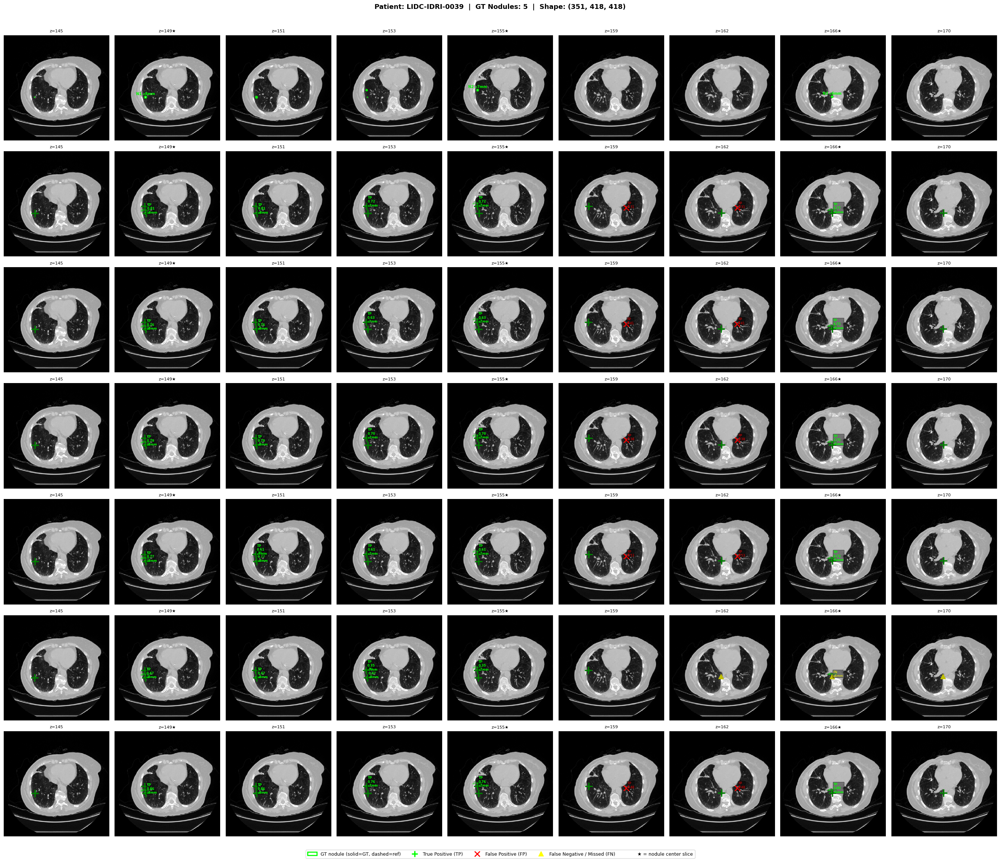


Saved: C:\Users\Administrator\desktop\unet\experiments\full_analysis\ct_detections_LIDC-IDRI-0039.png

Generating zoomed nodule views...


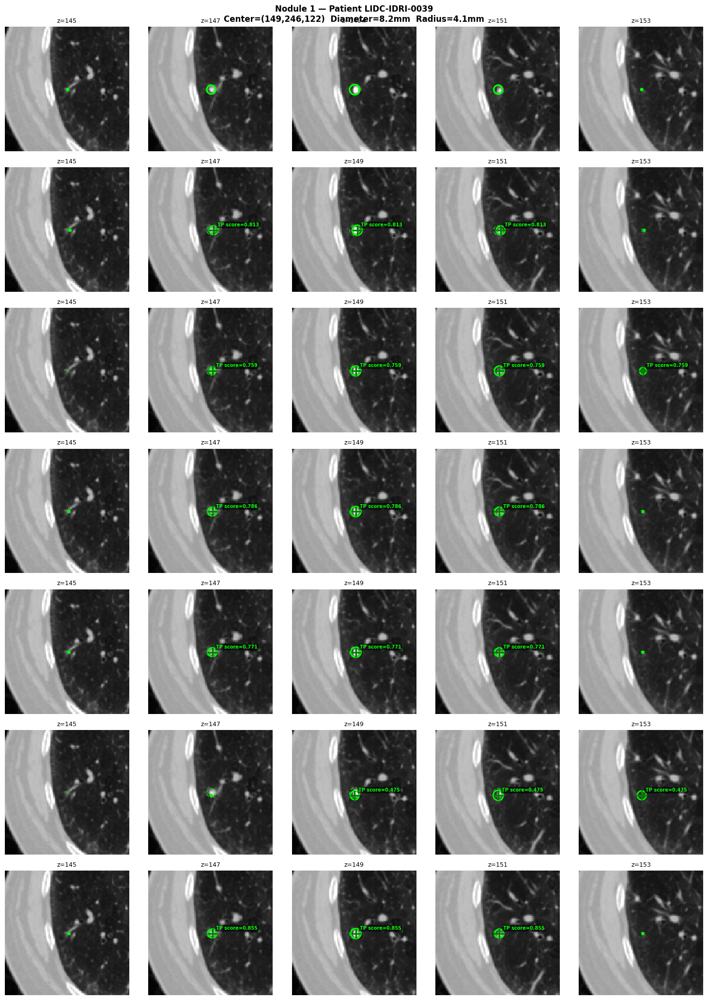

  Saved: nodule_1_LIDC-IDRI-0039.png  (⌀8.2mm)


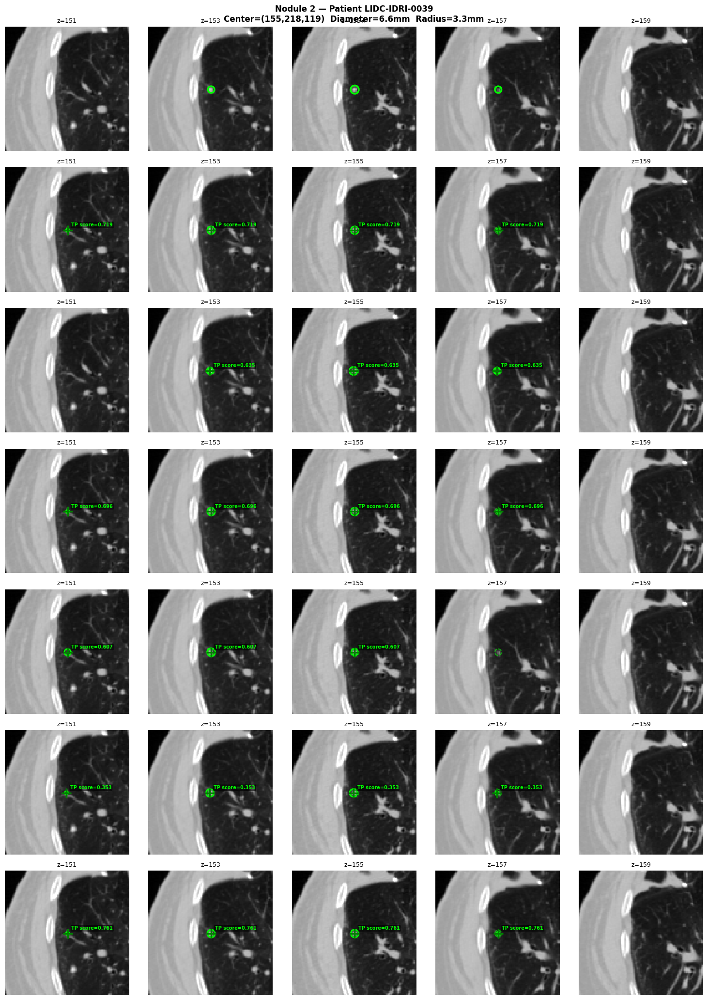

  Saved: nodule_2_LIDC-IDRI-0039.png  (⌀6.6mm)


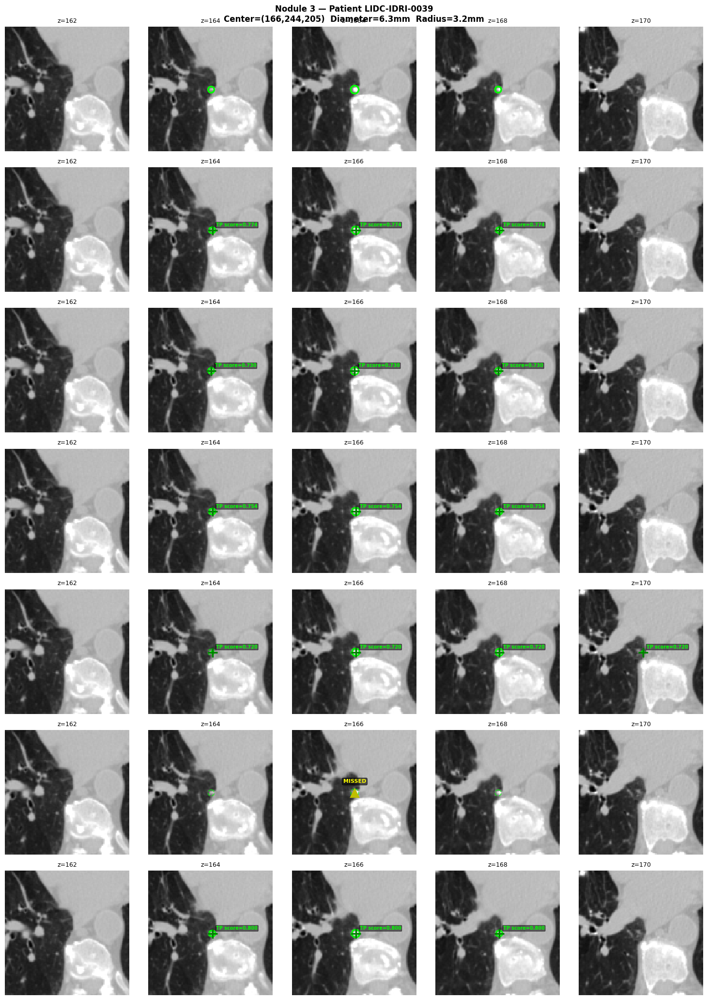

  Saved: nodule_3_LIDC-IDRI-0039.png  (⌀6.3mm)


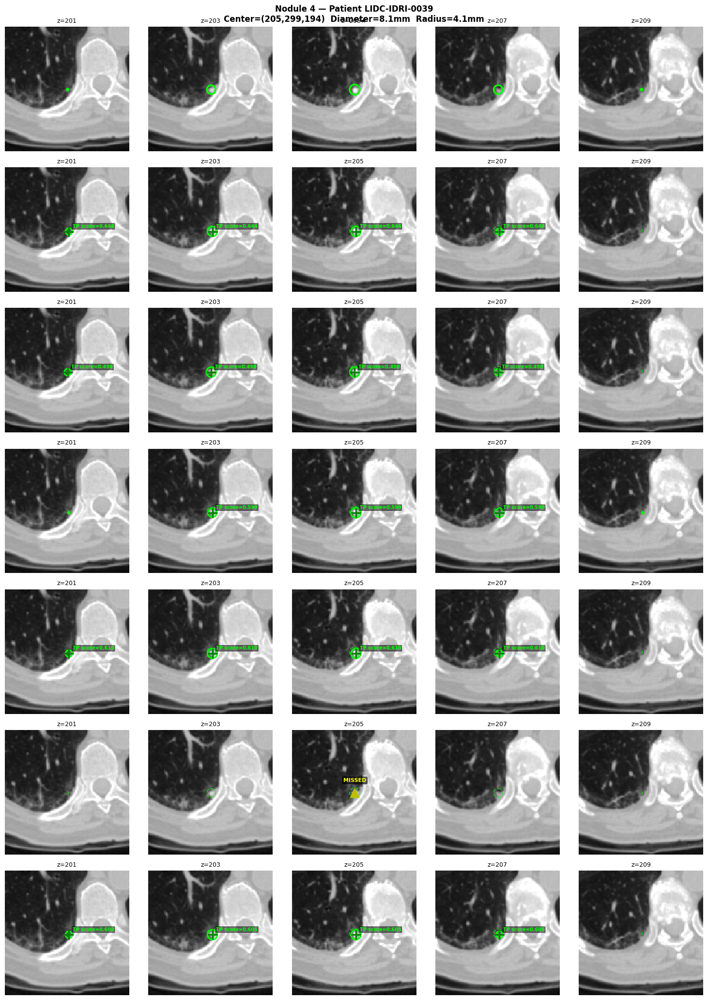

  Saved: nodule_4_LIDC-IDRI-0039.png  (⌀8.1mm)


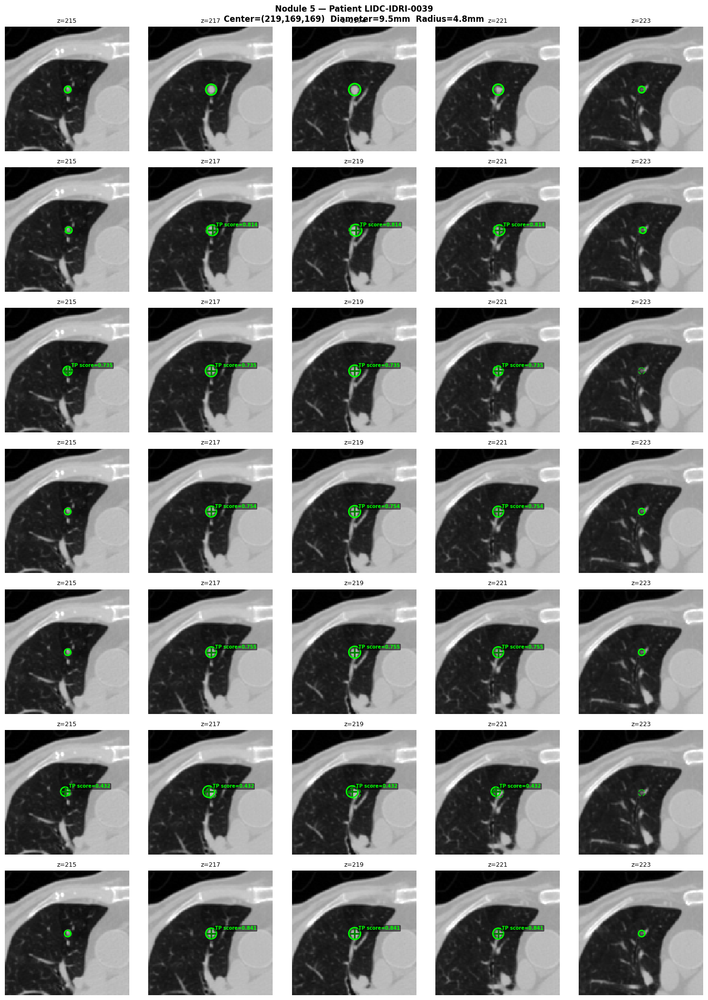

  Saved: nodule_5_LIDC-IDRI-0039.png  (⌀9.5mm)

VISUALIZATION COMPLETE
Patient : LIDC-IDRI-0039
Nodules : 5

Per-experiment results for this patient:
Experiment                           TP  FP  FN   Sens   Prec
────────────────────────────────────────────────────────────
  FedAvg Moderate                     5   6   0  1.000  0.455
  FedProx Moderate (μ=0.01)           5   2   0  1.000  0.714
  FedAvg Severe                       5   3   0  1.000  0.625
  FedProx Severe (μ=0.01)             5   2   0  1.000  0.714
  FedProx Severe (μ=0.10)             3   0   2  0.600  1.000
  DP-FedAvg Moderate (ε≈5)            5   6   0  1.000  0.455

Files saved:
  ct_detections_LIDC-IDRI-0039.png  ← full overview all slices
  nodule_1_LIDC-IDRI-0039.png  ← zoomed nodule 1 (⌀8.2mm)
  nodule_2_LIDC-IDRI-0039.png  ← zoomed nodule 2 (⌀6.6mm)
  nodule_3_LIDC-IDRI-0039.png  ← zoomed nodule 3 (⌀6.3mm)
  nodule_4_LIDC-IDRI-0039.png  ← zoomed nodule 4 (⌀8.1mm)
  nodule_5_LIDC-IDRI-0039.png  ← zoomed nodule

In [5]:
# CT VISUALIZATION — NO INFERENCE
# Uses saved PKL results only — no GPU needed
# Loads CT from .npy, draws detections from PKL
# Saves to: experiments/full_analysis/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT = OUT_ROOT / "experiments"
ANA_DIR  = EXP_ROOT / "full_analysis"
ANA_DIR.mkdir(parents=True, exist_ok=True)

# ── path routing ──────────────────────────────────────────────
with open(OUT_ROOT/"federation_splits.json") as f:
    orig_splits = json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT/"preprocessed",
                OUT_ROOT/"lung_masks",
                OUT_ROOT/"annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(
                f"client{cid}_pids",[]):
            cd = OUT_ROOT/f"client{cid}"
            return (cd/"preprocessed",
                    cd/"lung_masks",
                    cd/"annotations")
    raise ValueError(f"{pid} not found")

# ── load all experiment PKLs ──────────────────────────────────
print("Loading experiment results...")

exp_configs = {
    "FedAvg Moderate" : {
        "pkl"  : OUT_ROOT/"logs_global"/"global_all_results.pkl",
        "color": "steelblue",
        "group": "moderate",
    },
    "FedProx Moderate (μ=0.01)" : {
        "pkl"  : EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_results.pkl",
        "color": "green",
        "group": "moderate",
    },
    "FedAvg Severe"   : {
        "pkl"  : EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_results.pkl",
        "color": "darkorange",
        "group": "severe",
    },
    "FedProx Severe (μ=0.01)"   : {
        "pkl"  : EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_results.pkl",
        "color": "mediumorchid",
        "group": "severe",
    },
    "FedProx Severe (μ=0.10)"   : {
        "pkl"  : EXP_ROOT/"fedprox_severe"/"fedprox_severe_results.pkl",
        "color": "purple",
        "group": "severe",
    },
    "DP-FedAvg Moderate (ε≈5)"  : {
        "pkl"  : EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_results.pkl",
        "color": "teal",
        "group": "moderate",
    },
}

# build pid → results lookup per experiment
exp_data = {}
for name, cfg in exp_configs.items():
    p = Path(cfg["pkl"])
    if not p.exists():
        print(f"  ⚠  {name} — PKL not found")
        continue
    with open(p,"rb") as f:
        results = pickle.load(f)
    # build pid → record dict
    pid_map = {r["pid"]: r for r in results}
    exp_data[name] = {
        "pid_map": pid_map,
        "color"  : cfg["color"],
        "group"  : cfg["group"],
    }
    print(f"  ✓  {name} — {len(pid_map)} patients")

# ── find a good patient ───────────────────────────────────────
# want: patient present in ALL experiments,
#       has >= 2 GT nodules,
#       CT volume accessible

print("\nFinding suitable patient...")

# get pids common to all loaded experiments
all_pid_sets = [set(d["pid_map"].keys())
                for d in exp_data.values()]
common_pids  = set.intersection(*all_pid_sets) \
               if all_pid_sets else set()
print(f"Patients in all experiments: {len(common_pids)}")

CHOSEN_PID = None
chosen_gt  = None

for pid in sorted(common_pids):
    try:
        pd_dir,md_dir,ad_dir = get_patient_dirs(pid)
    except ValueError:
        continue
    vp = pd_dir/f"{pid}.npy"
    ap = ad_dir/f"{pid}.json"
    if not (vp.exists() and ap.exists()):
        continue
    with open(ap) as f:
        record = json.load(f)
    gt_nods = record["consensus_nodules"]
    if len(gt_nods) >= 2:
        CHOSEN_PID = pid
        chosen_gt  = gt_nods
        break

assert CHOSEN_PID is not None, \
    "No suitable patient found in common pool"

print(f"\nChosen patient : {CHOSEN_PID}")
print(f"GT nodules     : {len(chosen_gt)}")
for i,n in enumerate(chosen_gt):
    z,y,x = n['center_res']
    d = n['radius_mm']*2
    print(f"  Nodule {i+1}: center=({z},{y},{x})  "
          f"diameter={d:.1f}mm")

# load CT volume
pd_dir,_,_ = get_patient_dirs(CHOSEN_PID)
vol = np.load(pd_dir/f"{CHOSEN_PID}.npy")
print(f"Volume shape   : {vol.shape}")

# ── extract detections from PKL for chosen patient ────────────
def get_patient_detections(exp_name):
    """Returns tp_list, fp_list, fn_list for CHOSEN_PID."""
    pid_map = exp_data[exp_name]["pid_map"]
    if CHOSEN_PID not in pid_map:
        return [], [], []
    r = pid_map[CHOSEN_PID]
    return (r.get("tp_list",[]),
            r.get("fp_list",[]),
            r.get("fn_list",[]))

# ── find relevant slices ──────────────────────────────────────
nodule_slices = sorted(set(
    n['center_res'][0] for n in chosen_gt))

display_slices = set()
for z in nodule_slices:
    for dz in [-8,-4,0,4,8]:
        sz = z+dz
        if 0 <= sz < vol.shape[0]:
            display_slices.add(sz)
display_slices = sorted(display_slices)

# limit to 9 slices
if len(display_slices) > 9:
    keep = set(nodule_slices)
    for z in nodule_slices:
        keep.add(z-4); keep.add(z+4)
    display_slices = sorted(
        [z for z in keep if 0<=z<vol.shape[0]])[:9]

print(f"\nDisplay slices : {display_slices}")

# ── PLOT 1: FULL OVERVIEW ─────────────────────────────────────
n_exps   = len(exp_data)
n_slices = len(display_slices)
n_rows   = 1 + n_exps  # row 0 = CT+GT, rest = experiments

fig, axes = plt.subplots(
    n_rows, n_slices,
    figsize=(n_slices*3, n_rows*3.2))

if n_rows == 1:   axes = axes[np.newaxis,:]
if n_slices == 1: axes = axes[:,np.newaxis]

fig.suptitle(
    f"Patient: {CHOSEN_PID}  |  "
    f"GT Nodules: {len(chosen_gt)}  |  "
    f"Shape: {vol.shape}",
    fontsize=13, fontweight='bold', y=1.01)

# ── row 0: CT + GT only ───────────────────────────────────────
for col, z in enumerate(display_slices):
    ax = axes[0, col]
    ax.imshow(vol[z], cmap='gray',
              vmin=0, vmax=1,
              interpolation='nearest')
    for ni, nod in enumerate(chosen_gt):
        gz,gy,gx = nod['center_res']
        r_mm     = nod['radius_mm']
        diam_mm  = r_mm * 2
        if abs(gz-z) <= r_mm:
            r_slice = np.sqrt(
                max(0, r_mm**2-(gz-z)**2))
            circle = plt.Circle(
                (gx,gy), r_slice,
                fill=False, color='lime',
                linewidth=2, linestyle='-')
            ax.add_patch(circle)
            if gz == z:
                ax.text(gx, gy-r_slice-3,
                        f'N{ni+1} ⌀{diam_mm:.0f}mm',
                        color='lime', fontsize=7,
                        ha='center', va='bottom',
                        fontweight='bold')
    star = "★" if z in nodule_slices else ""
    ax.set_title(f'z={z}{star}', fontsize=8)
    if col == 0:
        ax.set_ylabel('CT + GT Nodules\n'
                      '(lime=nodule boundary)',
                      fontsize=7)
    ax.axis('off')

# ── rows 1+: one per experiment ───────────────────────────────
for row_idx, (exp_name, edata) in enumerate(
        exp_data.items()):
    row   = row_idx + 1
    color = edata["color"]
    tp_list, fp_list, fn_list = \
        get_patient_detections(exp_name)

    # build position lookup
    tp_pos = {}
    for t in tp_list:
        det = t.get('det',(0,0,0,0))
        if isinstance(det,(list,tuple)) and len(det)>=3:
            tp_pos[(int(det[0]),int(det[1]),
                    int(det[2]))] = t

    fp_pos = {}
    for f_ in fp_list:
        det = f_.get('det',(0,0,0,0))
        if isinstance(det,(list,tuple)) and len(det)>=3:
            fp_pos[(int(det[0]),int(det[1]),
                    int(det[2]))] = f_

    for col, z in enumerate(display_slices):
        ax = axes[row, col]
        ax.imshow(vol[z], cmap='gray',
                  vmin=0, vmax=1,
                  interpolation='nearest')

        # GT circles (faint dashed)
        for ni, nod in enumerate(chosen_gt):
            gz,gy,gx = nod['center_res']
            r_mm     = nod['radius_mm']
            if abs(gz-z) <= r_mm:
                r_slice = np.sqrt(
                    max(0, r_mm**2-(gz-z)**2))
                circle = plt.Circle(
                    (gx,gy), r_slice,
                    fill=False, color='lime',
                    linewidth=1.2,
                    linestyle='--', alpha=0.6)
                ax.add_patch(circle)
                if gz == z:
                    diam = nod['radius_mm']*2
                    ax.text(gx,gy-r_slice-2,
                            f'⌀{diam:.0f}mm',
                            color='lime',fontsize=6,
                            ha='center',va='bottom')

        # TP markers
        for (dz,dy,dx), t in tp_pos.items():
            if abs(dz-z) > 6: continue
            det = t['det']
            sc  = float(det[3]) if len(det)>3 else 0
            r_mm = t['gt'].get('radius_mm',5) \
                   if 'gt' in t else 5
            diam = r_mm*2
            # draw circle at detection
            if abs(dz-z) <= r_mm:
                r_s = np.sqrt(max(0,r_mm**2-(dz-z)**2))
                circ = plt.Circle(
                    (dx,dy),r_s,
                    fill=False,color='lime',
                    linewidth=2,linestyle='-',
                    alpha=0.9)
                ax.add_patch(circ)
            ax.plot(dx,dy,'g+',
                    markersize=14,markeredgewidth=2.5)
            if abs(dz-z) <= 2:
                ax.text(dx+4,dy,
                        f'TP\n{sc:.2f}\n⌀{diam:.0f}mm',
                        color='lime',fontsize=6,
                        fontweight='bold',
                        bbox=dict(boxstyle='round,pad=0.1',
                                  facecolor='black',
                                  alpha=0.4))

        # FP markers
        for (dz,dy,dx), f_ in fp_pos.items():
            if abs(dz-z) > 4: continue
            det = f_.get('det',(dz,dy,dx,0))
            sc  = float(det[3]) if len(det)>3 else 0
            ax.plot(dx,dy,'rx',
                    markersize=10,markeredgewidth=2)
            if abs(dz-z) <= 2:
                ax.text(dx+4,dy,
                        f'FP\n{sc:.2f}',
                        color='red',fontsize=6,
                        bbox=dict(boxstyle='round,pad=0.1',
                                  facecolor='black',
                                  alpha=0.4))

        # FN markers
        for fn_item in fn_list:
            gt = fn_item.get('gt',{})
            if not gt: continue
            gz,gy,gx = gt['center_res']
            r_mm = gt.get('radius_mm',5)
            diam = r_mm*2
            if abs(gz-z) > 4: continue
            ax.plot(gx,gy,'y^',
                    markersize=9,markeredgewidth=1.5)
            if abs(gz-z) <= 2:
                ax.text(gx+4,gy,
                        f'FN\n⌀{diam:.0f}mm',
                        color='yellow',fontsize=6,
                        bbox=dict(boxstyle='round,pad=0.1',
                                  facecolor='black',
                                  alpha=0.4))

        star = "★" if z in nodule_slices else ""
        ax.set_title(f'z={z}{star}', fontsize=8)

        if col == 0:
            n_tp = len(tp_list)
            n_fp = len(fp_list)
            n_fn = len(fn_list)
            sens = n_tp/max(n_tp+n_fn,1)
            prec = n_tp/max(n_tp+n_fp,1)
            ax.set_ylabel(
                f'{exp_name}\n'
                f'TP={n_tp} FP={n_fp} FN={n_fn}\n'
                f'Sens={sens:.2f} Prec={prec:.2f}',
                fontsize=6.5)
        ax.axis('off')

# legend
legend_elements = [
    mpatches.Patch(facecolor='none',
                   edgecolor='lime',linewidth=2,
                   linestyle='-',
                   label='GT nodule (solid=GT, dashed=ref)'),
    plt.Line2D([0],[0],marker='+',color='w',
               markerfacecolor='lime',markersize=12,
               markeredgecolor='lime',markeredgewidth=2.5,
               label='True Positive (TP)'),
    plt.Line2D([0],[0],marker='x',color='w',
               markerfacecolor='red',markersize=10,
               markeredgecolor='red',markeredgewidth=2,
               label='False Positive (FP)'),
    plt.Line2D([0],[0],marker='^',color='w',
               markerfacecolor='yellow',markersize=9,
               markeredgecolor='yellow',markeredgewidth=1.5,
               label='False Negative / Missed (FN)'),
    plt.Line2D([0],[0],color='none',
               label='★ = nodule center slice'),
]
fig.legend(handles=legend_elements,
           loc='lower center', ncol=5,
           fontsize=9,
           bbox_to_anchor=(0.5,-0.02),
           frameon=True)

plt.tight_layout()
out_path = ANA_DIR/f"ct_detections_{CHOSEN_PID}.png"
assert not out_path.exists(), \
    f"Would overwrite {out_path}"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_path}")

# ── PLOT 2: ZOOMED PER NODULE ────────────────────────────────
print("\nGenerating zoomed nodule views...")

for ni, nod in enumerate(chosen_gt):
    gz,gy,gx = nod['center_res']
    r_mm     = nod['radius_mm']
    diam_mm  = r_mm*2
    crop_r   = max(50, int(r_mm*4))

    z_slices = [gz-4,gz-2,gz,gz+2,gz+4]
    z_slices = [z for z in z_slices
                if 0<=z<vol.shape[0]]

    y1c = max(0, gy-crop_r)
    y2c = min(vol.shape[1], gy+crop_r)
    x1c = max(0, gx-crop_r)
    x2c = min(vol.shape[2], gx+crop_r)
    cy  = gy-y1c
    cx  = gx-x1c

    n_rows_z = 1 + len(exp_data)
    n_cols_z = len(z_slices)

    fig2, axes2 = plt.subplots(
        n_rows_z, n_cols_z,
        figsize=(n_cols_z*3, n_rows_z*3))

    if n_rows_z==1: axes2=axes2[np.newaxis,:]
    if n_cols_z==1: axes2=axes2[:,np.newaxis]

    fig2.suptitle(
        f"Nodule {ni+1} — Patient {CHOSEN_PID}\n"
        f"Center=({gz},{gy},{gx})  "
        f"Diameter={diam_mm:.1f}mm  "
        f"Radius={r_mm:.1f}mm",
        fontsize=12, fontweight='bold')

    for col, z in enumerate(z_slices):
        r_slice = np.sqrt(max(0,r_mm**2-(gz-z)**2))

        # row 0: CT + GT
        ax = axes2[0, col]
        crop = vol[z,y1c:y2c,x1c:x2c]
        ax.imshow(crop,cmap='gray',
                  vmin=0,vmax=1,
                  interpolation='nearest')
        if r_slice > 0:
            circle = plt.Circle(
                (cx,cy), r_slice,
                fill=False, color='lime',
                linewidth=2.5)
            ax.add_patch(circle)
        star = "★" if z==gz else ""
        ax.set_title(f'z={z}{star}', fontsize=9)
        if col==0:
            ax.set_ylabel(
                f'CT + GT\n⌀{diam_mm:.1f}mm',
                fontsize=8)
        ax.axis('off')

        # rows 1+: experiment detections
        for ridx, (exp_name, edata) in enumerate(
                exp_data.items()):
            ax    = axes2[ridx+1, col]
            color = edata["color"]
            tp_list,fp_list,fn_list = \
                get_patient_detections(exp_name)

            crop = vol[z,y1c:y2c,x1c:x2c]
            ax.imshow(crop,cmap='gray',
                      vmin=0,vmax=1,
                      interpolation='nearest')

            # GT reference circle
            if r_slice > 0:
                circle = plt.Circle(
                    (cx,cy),r_slice,
                    fill=False,color='lime',
                    linewidth=1.5,linestyle='--',
                    alpha=0.6)
                ax.add_patch(circle)

            # check if this nodule was TP or FN
            nodule_status = "FN"
            for t in tp_list:
                gt_ref = t.get('gt',{})
                if not gt_ref: continue
                tgz,tgy,tgx = gt_ref['center_res']
                if (tgz==gz and tgy==gy and tgx==gx):
                    nodule_status = "TP"
                    det = t['det']
                    dz2=int(det[0]); dy2=int(det[1])
                    dx2=int(det[2]); sc=float(det[3])
                    # detection position in crop coords
                    dcy = dy2-y1c
                    dcx = dx2-x1c
                    if abs(dz2-z) <= r_mm:
                        r_det = np.sqrt(
                            max(0,r_mm**2-(dz2-z)**2))
                        circ2 = plt.Circle(
                            (dcx,dcy),r_det,
                            fill=False,color='lime',
                            linewidth=2,linestyle='-')
                        ax.add_patch(circ2)
                    if abs(dz2-z) <= 3:
                        ax.plot(dcx,dcy,'g+',
                                markersize=14,
                                markeredgewidth=2.5)
                        ax.text(
                            dcx+3,dcy-3,
                            f'TP score={sc:.3f}',
                            color='lime',fontsize=7,
                            fontweight='bold',
                            bbox=dict(
                                boxstyle='round,pad=0.1',
                                facecolor='black',
                                alpha=0.5))
                    break

            if nodule_status == "FN" and z==gz:
                ax.plot(cx,cy,'y^',
                        markersize=12,
                        markeredgewidth=2)
                ax.text(cx,cy-r_slice-4,
                        'MISSED',
                        color='yellow',fontsize=8,
                        ha='center',va='bottom',
                        fontweight='bold',
                        bbox=dict(
                            boxstyle='round,pad=0.2',
                            facecolor='black',
                            alpha=0.6))

            # also show nearby FPs in this crop
            for fp_ in fp_list:
                det = fp_.get('det',(0,0,0,0))
                if not (isinstance(det,(list,tuple))
                        and len(det)>=3): continue
                dz2=int(det[0]); dy2=int(det[1])
                dx2=int(det[2])
                sc =float(det[3]) if len(det)>3 else 0
                # only show if within crop bounds
                if (abs(dz2-z)<=4 and
                    y1c<=dy2<y2c and
                    x1c<=dx2<x2c):
                    dcy2=dy2-y1c; dcx2=dx2-x1c
                    ax.plot(dcx2,dcy2,'rx',
                            markersize=9,
                            markeredgewidth=2)
                    if abs(dz2-z)<=2:
                        ax.text(dcx2+3,dcy2,
                                f'FP\n{sc:.2f}',
                                color='red',fontsize=6)

            ax.set_title(f'z={z}', fontsize=9)
            if col==0:
                n_tp=len(tp_list)
                n_fp=len(fp_list)
                n_fn=len(fn_list)
                sens=n_tp/max(n_tp+n_fn,1)
                status_str = (
                    f'TP ✓' if nodule_status=="TP"
                    else 'MISSED ✗')
                ax.set_ylabel(
                    f'{exp_name}\n'
                    f'{status_str}\n'
                    f'Global: Sens={sens:.2f}',
                    fontsize=6.5)
            ax.axis('off')

    plt.tight_layout()
    out_z = ANA_DIR/f"nodule_{ni+1}_{CHOSEN_PID}.png"
    assert not out_z.exists(), \
        f"Would overwrite {out_z}"
    plt.savefig(out_z, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"  Saved: nodule_{ni+1}_{CHOSEN_PID}.png  "
          f"(⌀{diam_mm:.1f}mm)")

# ── SUMMARY ───────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"VISUALIZATION COMPLETE")
print(f"{'='*55}")
print(f"Patient : {CHOSEN_PID}")
print(f"Nodules : {len(chosen_gt)}")
print(f"\nPer-experiment results for this patient:")
print(f"{'Experiment':<35} {'TP':>3} {'FP':>3} "
      f"{'FN':>3} {'Sens':>6} {'Prec':>6}")
print(f"{'─'*60}")
for exp_name in exp_data:
    tp,fp,fn = get_patient_detections(exp_name)
    n_tp=len(tp); n_fp=len(fp); n_fn=len(fn)
    sens=n_tp/max(n_tp+n_fn,1)
    prec=n_tp/max(n_tp+n_fp,1)
    print(f"  {exp_name:<33} {n_tp:>3} {n_fp:>3} "
          f"{n_fn:>3} {sens:>6.3f} {prec:>6.3f}")

print(f"\nFiles saved:")
print(f"  ct_detections_{CHOSEN_PID}.png  "
      f"← full overview all slices")
for ni,nod in enumerate(chosen_gt):
    diam = nod['radius_mm']*2
    print(f"  nodule_{ni+1}_{CHOSEN_PID}.png  "
          f"← zoomed nodule {ni+1} (⌀{diam:.1f}mm)")

Device: cuda

Verifying model files:
  ✓  FedAvg Moderate
         global_fl_final.pt
  ✓  FedProx Moderate μ=0.01
         global_fedprox_moderate_final.pt
  ✓  FedAvg Severe
         global_fl_severe_final.pt
  ✓  FedProx Severe μ=0.01
         global_fedprox_severe_final.pt
  ✓  FedProx Severe μ=0.10
         global_fedprox_severe_final.pt
  ✓  DP-FedAvg Moderate ε≈5
         global_dp_fedavg_moderate_e5_final.pt

6/6 models available

Selected patients:
  Case A: Large nodule, all detected
    PID=LIDC-IDRI-0001  nodules=1  diameters=['32.8mm']
    FedAvg: TP=1 FP=2 FN=0
  Case B: Multiple nodules
    PID=LIDC-IDRI-0012  nodules=9  diameters=['5.9mm', '7.0mm', '6.1mm', '12.7mm', '7.5mm', '7.9mm', '8.3mm', '7.1mm', '6.8mm']
    FedAvg: TP=9 FP=9 FN=0
  Case C: Challenging / small nodule
    PID=LIDC-IDRI-0018  nodules=4  diameters=['5.8mm', '11.6mm', '8.1mm', '21.8mm']
    FedAvg: TP=4 FP=3 FN=0

INFERENCE — 3 patients × 6 models = 18 runs

──────────────────────────────────────────

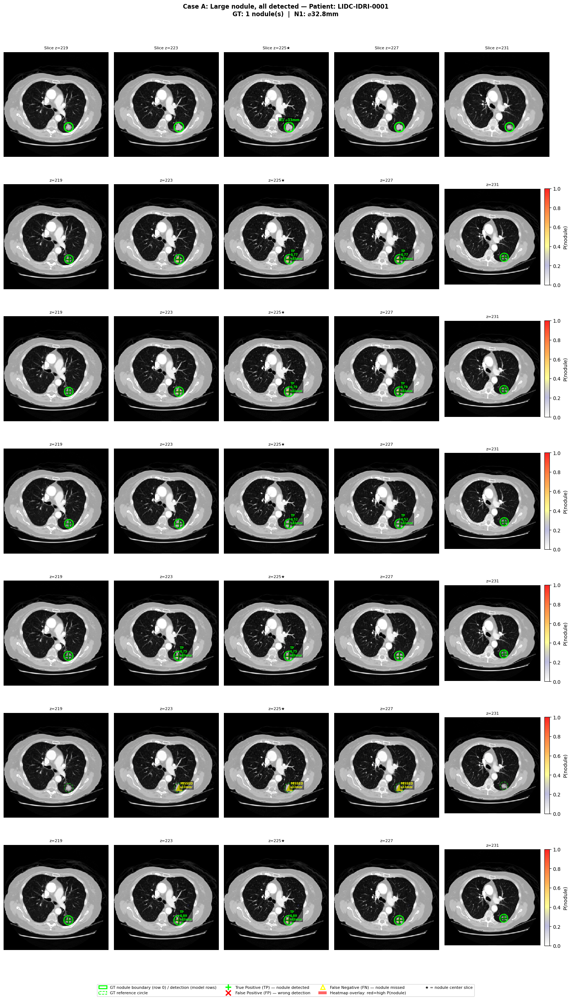

  Saved: heatmap_LIDC_IDRI_0001.png


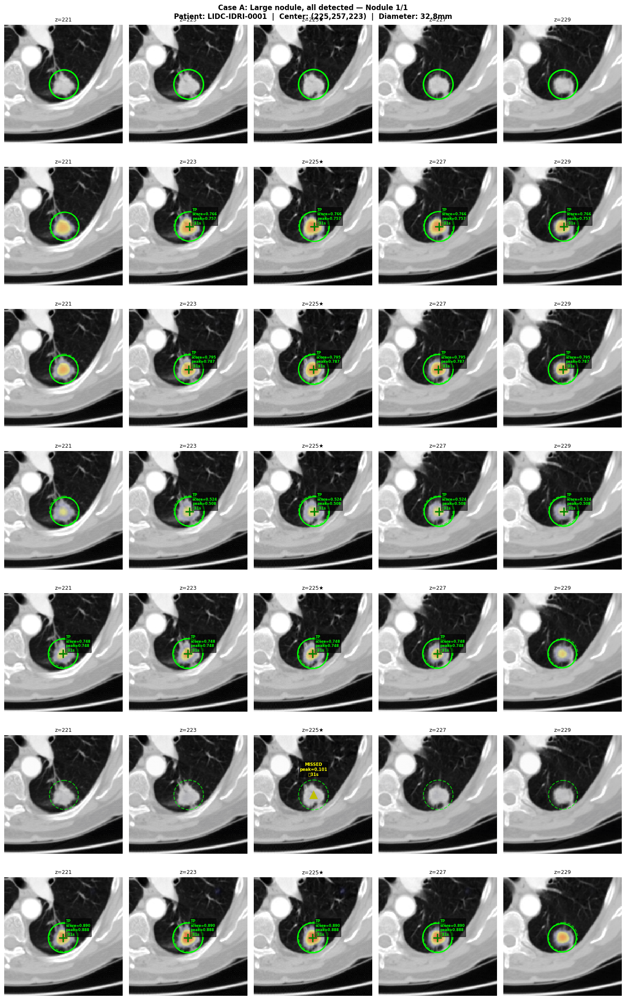

  Saved: nodule_1_LIDC_IDRI_0001.png  ⌀32.8mm


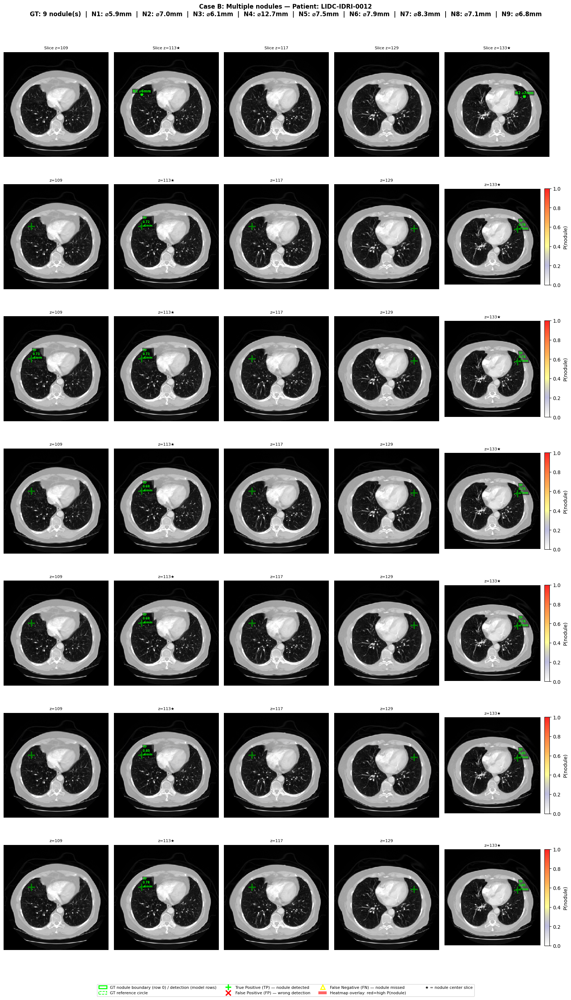

  Saved: heatmap_LIDC_IDRI_0012.png


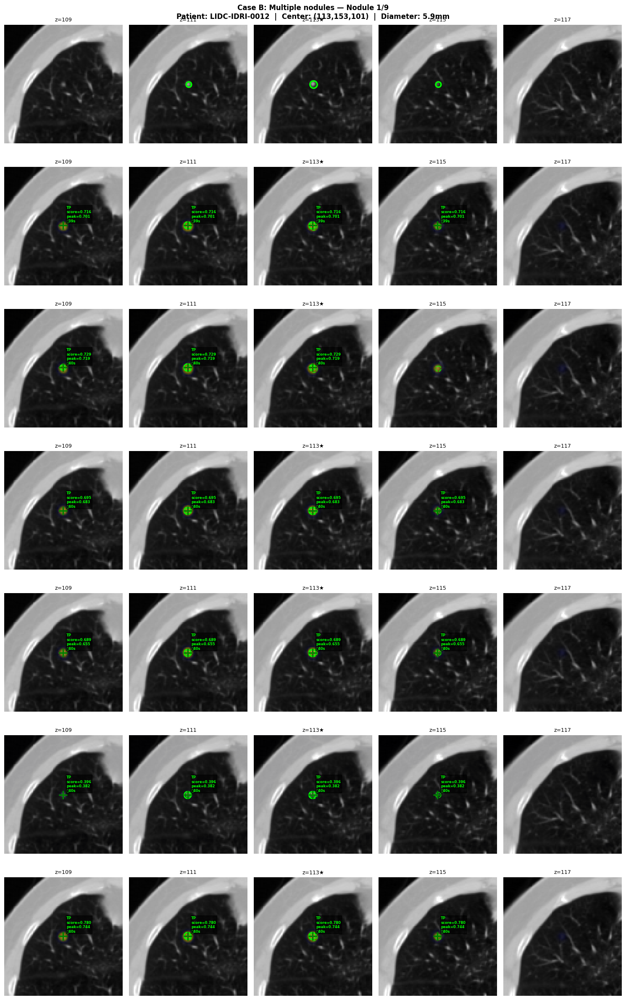

  Saved: nodule_1_LIDC_IDRI_0012.png  ⌀5.9mm


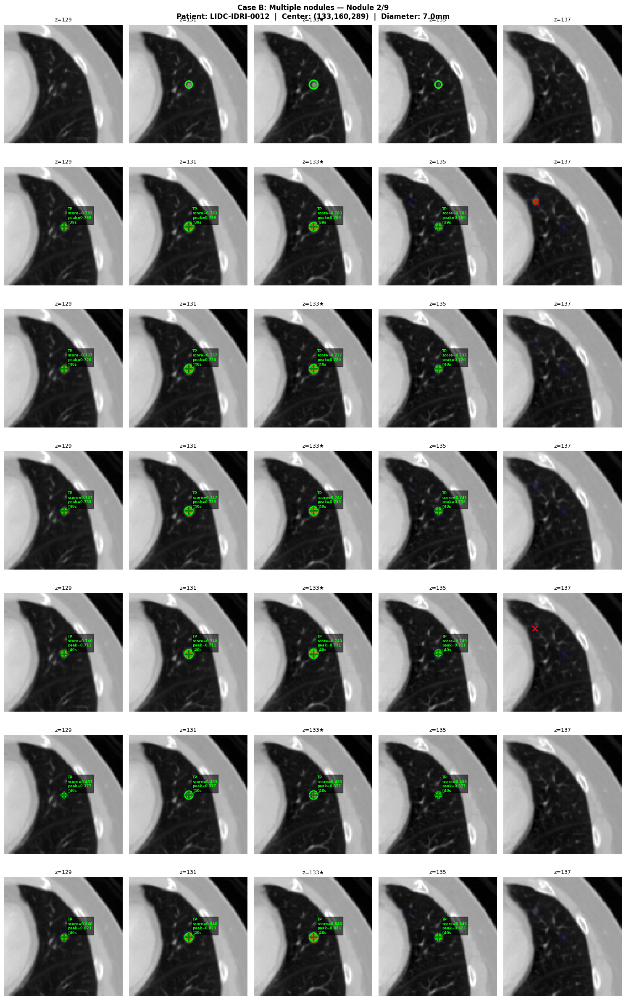

  Saved: nodule_2_LIDC_IDRI_0012.png  ⌀7.0mm


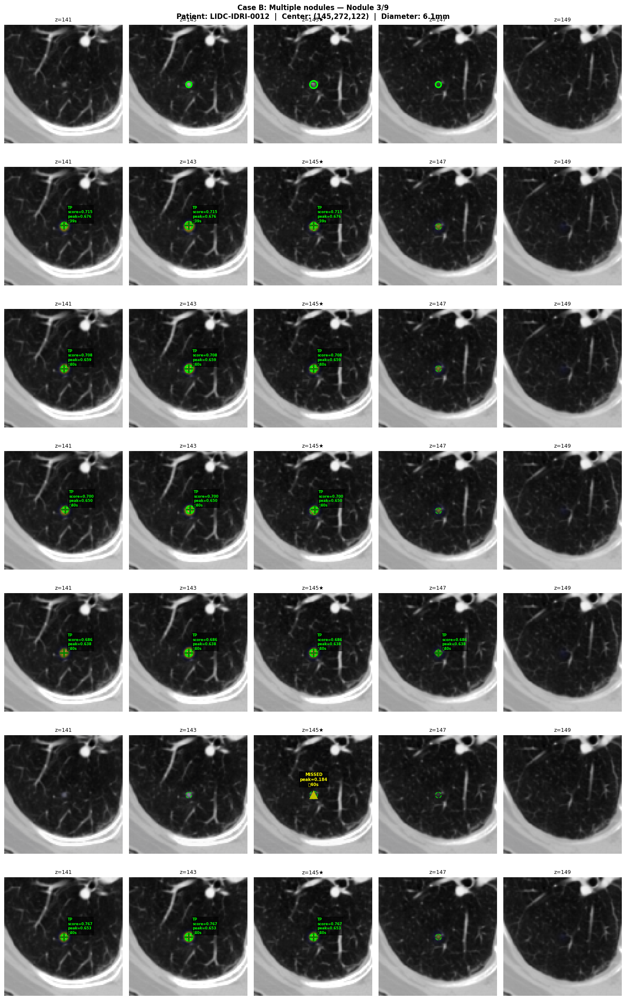

  Saved: nodule_3_LIDC_IDRI_0012.png  ⌀6.1mm


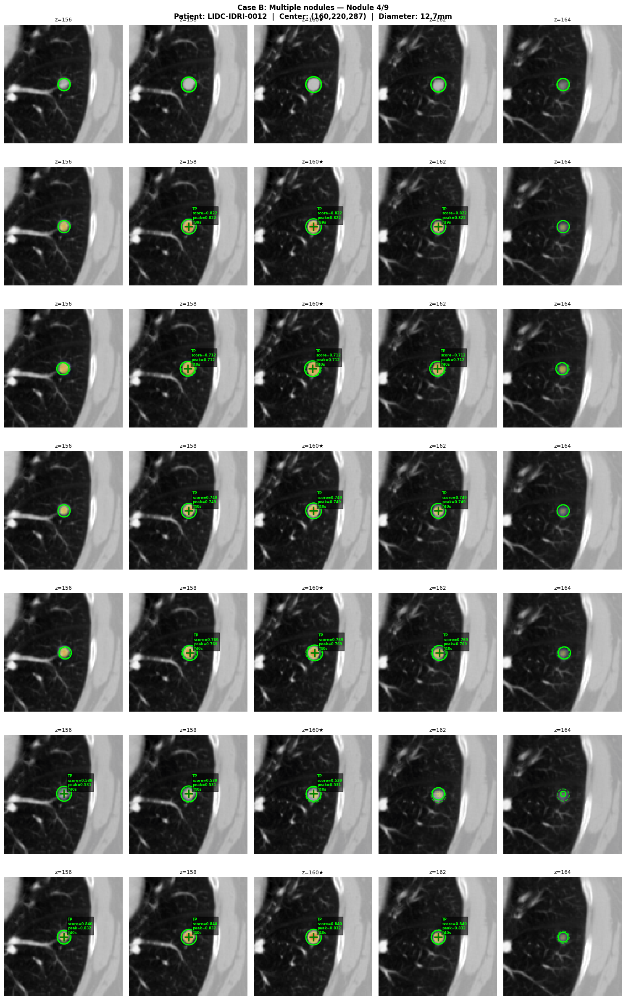

  Saved: nodule_4_LIDC_IDRI_0012.png  ⌀12.7mm


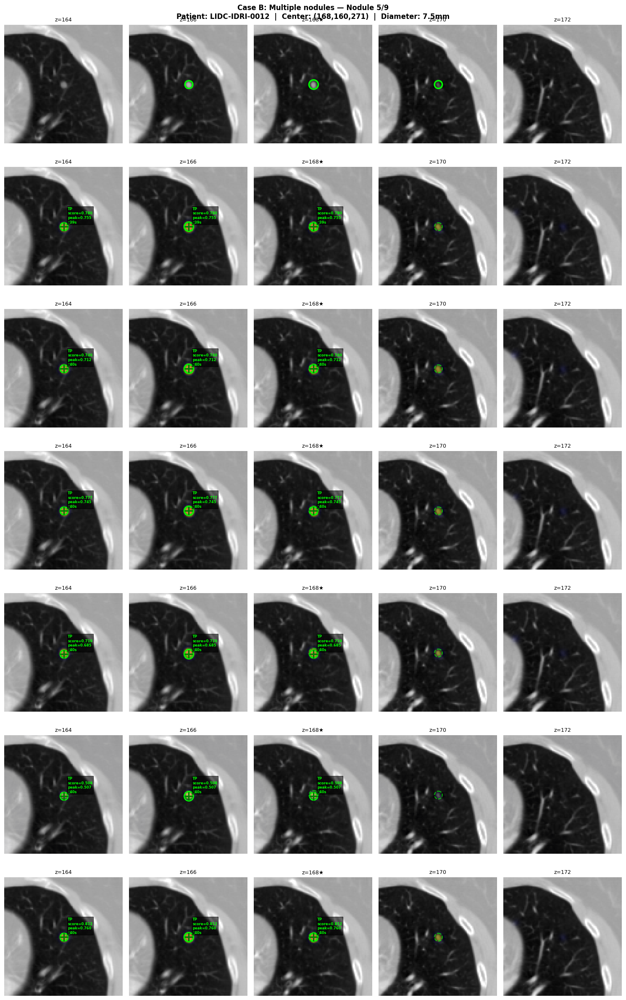

  Saved: nodule_5_LIDC_IDRI_0012.png  ⌀7.5mm


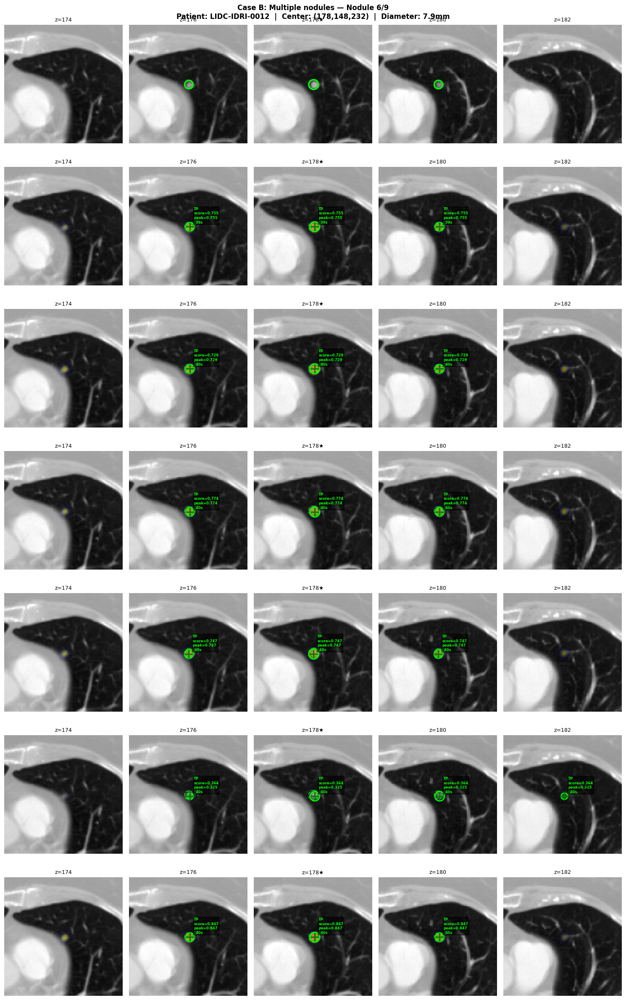

  Saved: nodule_6_LIDC_IDRI_0012.png  ⌀7.9mm


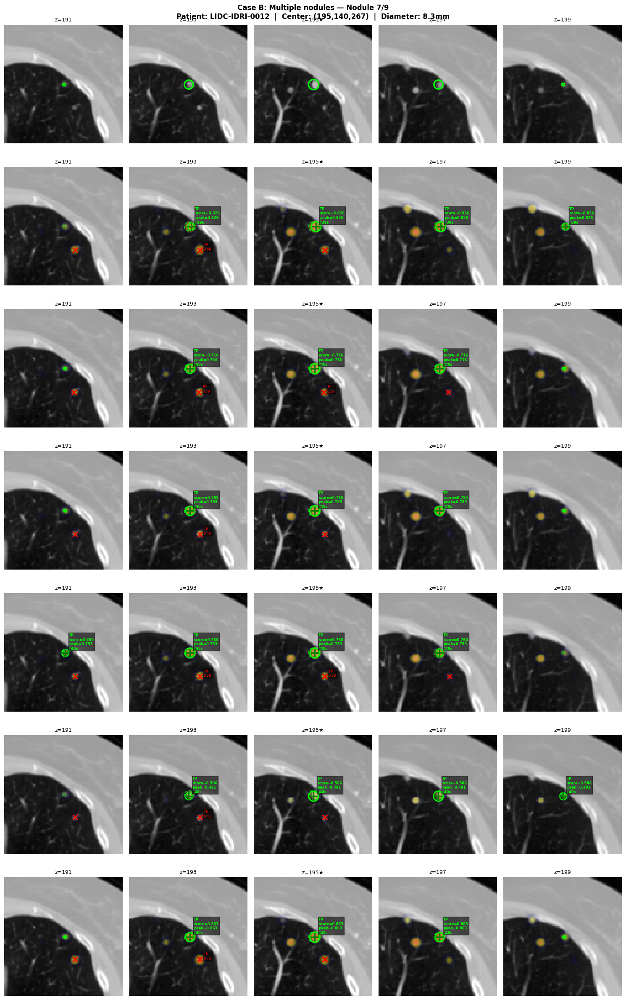

  Saved: nodule_7_LIDC_IDRI_0012.png  ⌀8.3mm


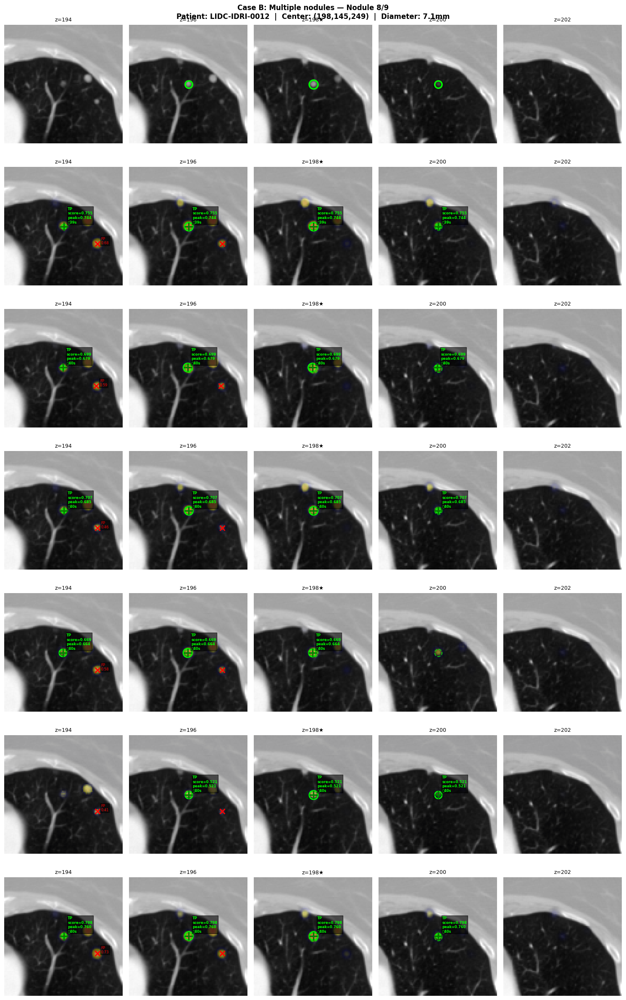

  Saved: nodule_8_LIDC_IDRI_0012.png  ⌀7.1mm


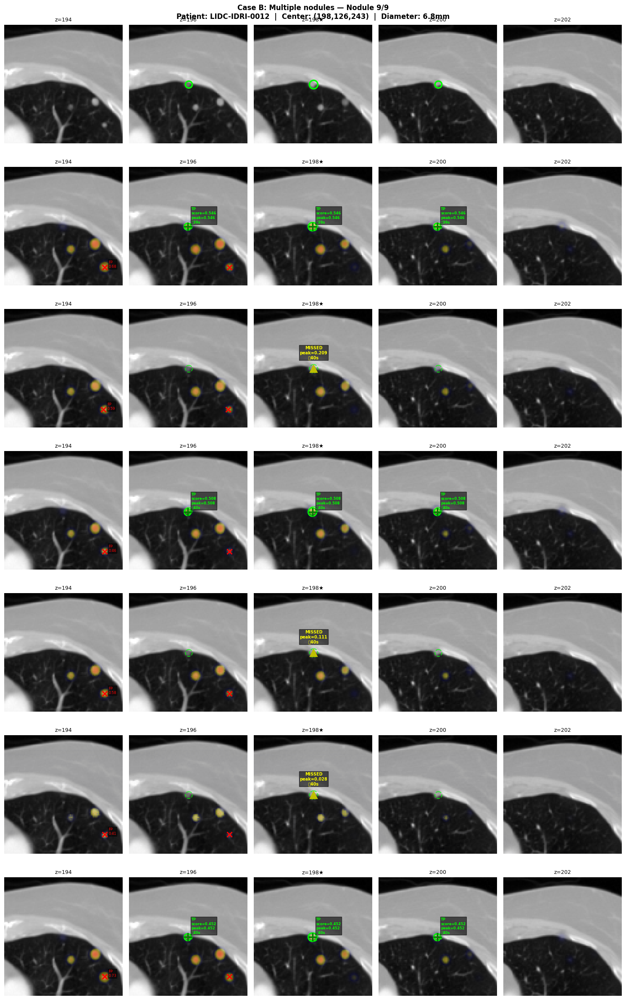

  Saved: nodule_9_LIDC_IDRI_0012.png  ⌀6.8mm


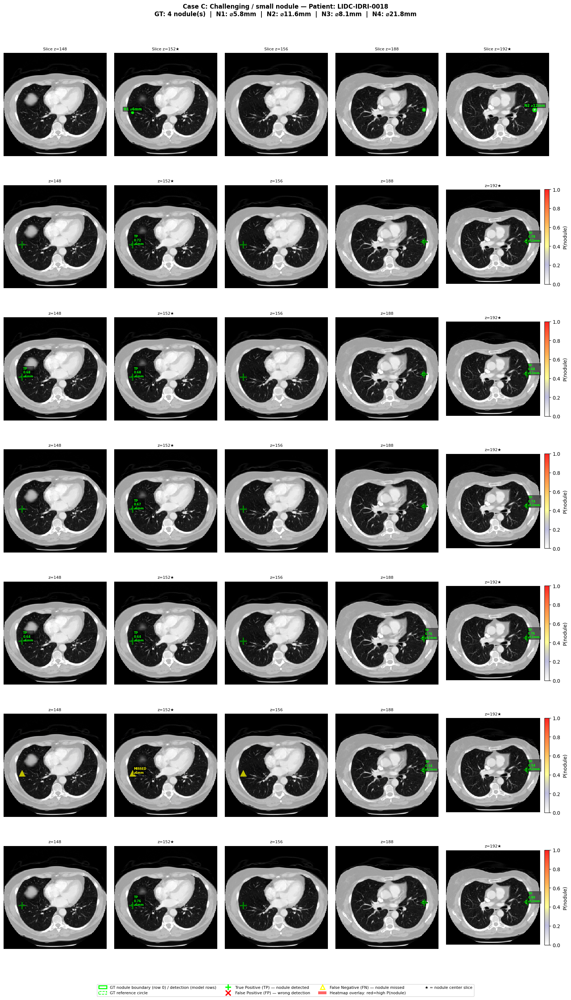

  Saved: heatmap_LIDC_IDRI_0018.png


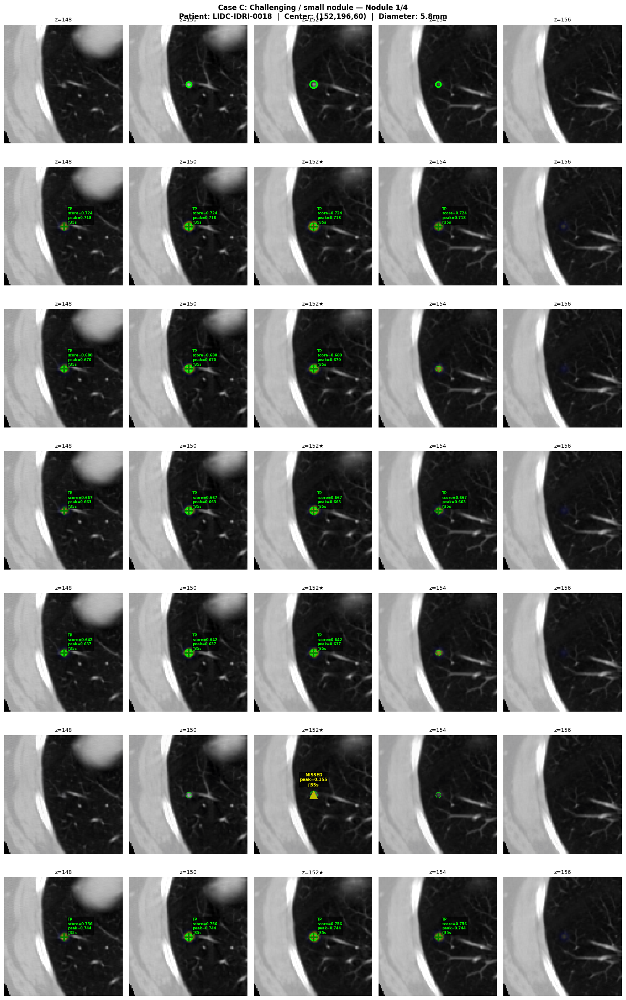

  Saved: nodule_1_LIDC_IDRI_0018.png  ⌀5.8mm


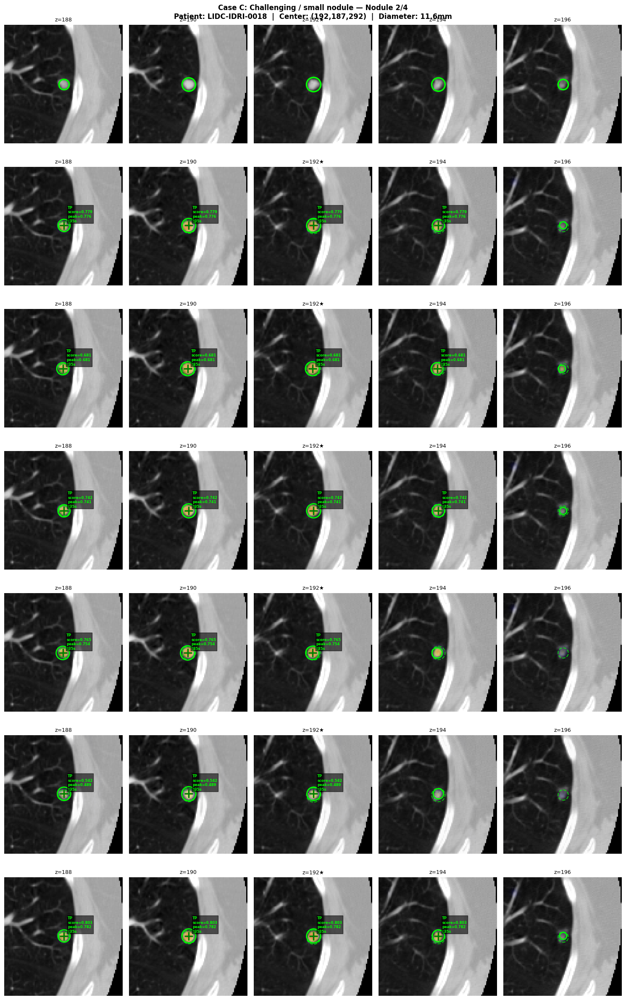

  Saved: nodule_2_LIDC_IDRI_0018.png  ⌀11.6mm


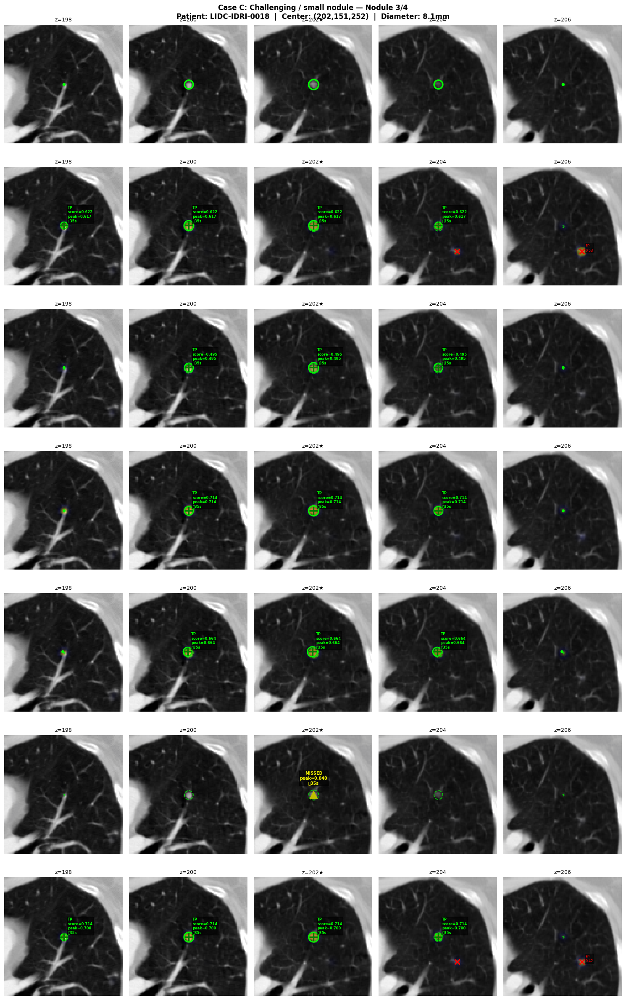

  Saved: nodule_3_LIDC_IDRI_0018.png  ⌀8.1mm


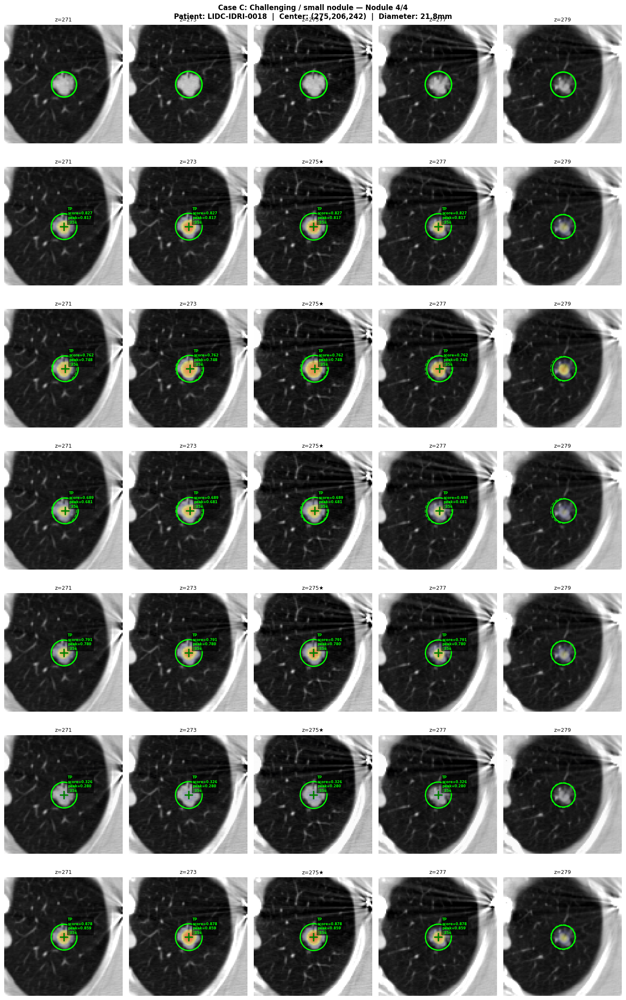

  Saved: nodule_4_LIDC_IDRI_0018.png  ⌀21.8mm

TIMING SUMMARY
Model                                               Case A      Case B      Case C      Mean
─────────────────────────────────────────────────────────────────────────────────────
FedAvg Moderate                                        31s         39s         35s       35s
FedProx Moderate μ=0.01                                31s         40s         35s       35s
FedAvg Severe                                          31s         40s         35s       35s
FedProx Severe μ=0.01                                  31s         40s         35s       35s
FedProx Severe μ=0.10                                  31s         40s         35s       35s
DP-FedAvg Moderate ε≈5                                 31s         40s         35s       35s

Total runs    : 18
Total time    : 12m24s
Mean per run  : 41.4s

Files saved to: C:\Users\Administrator\desktop\unet\experiments\full_analysis\heatmaps
  heatmap_LIDC_IDRI_0001.png
  heatmap_LIDC_IDRI

In [4]:
# CT HEATMAP VISUALIZATION — FIXED MODEL ORDER + LABELS
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import maximum_filter
from pathlib import Path
import json, pickle, time
import warnings
warnings.filterwarnings('ignore')

OUT_ROOT    = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT    = OUT_ROOT / "experiments"
ANA_DIR     = EXP_ROOT / "full_analysis"
HEATMAP_DIR = ANA_DIR / "heatmaps"
HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'
PATCH_SIZE   = 96
STRIDE       = 20
THRESHOLD    = 0.3
BASE_FILTERS = 32
overall_start = time.time()

print(f"Device: {DEVICE}")

# ── UNet ─────────────────────────────────────────────────────
class DoubleConv3D(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.block=nn.Sequential(
            nn.Conv3d(in_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True),
            nn.Conv3d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm3d(out_ch),nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)
class Down(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.pool=nn.MaxPool3d(2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x): return self.conv(self.pool(x))
class Up(nn.Module):
    def __init__(self,c1,c2):
        super().__init__()
        self.up=nn.ConvTranspose3d(c1,c2,2,stride=2)
        self.conv=DoubleConv3D(c1,c2)
    def forward(self,x,skip):
        return self.conv(torch.cat([skip,self.up(x)],dim=1))
class UNet3D(nn.Module):
    def __init__(self,base_filters=32):
        super().__init__()
        f=base_filters
        self.enc1=DoubleConv3D(1,f); self.enc2=Down(f,f*2)
        self.enc3=Down(f*2,f*4);     self.enc4=Down(f*4,f*8)
        self.bottleneck=Down(f*8,f*16)
        self.dec4=Up(f*16,f*8); self.dec3=Up(f*8,f*4)
        self.dec2=Up(f*4,f*2);  self.dec1=Up(f*2,f)
        self.head=nn.Conv3d(f,1,1)
    def forward(self,x):
        e1=self.enc1(x); e2=self.enc2(e1)
        e3=self.enc3(e2); e4=self.enc4(e3)
        b=self.bottleneck(e4)
        return torch.sigmoid(self.head(
            self.dec1(self.dec2(self.dec3(
                self.dec4(b,e4),e3),e2),e1)))

def sliding_window_max(model,vol,mask,ps,stride,device):
    D,H,W=vol.shape; p=ps
    heatmap=np.zeros((D,H,W),dtype=np.float32)
    coords=np.argwhere(mask>0)
    if len(coords)==0: return heatmap,0
    z1=max(0,coords[:,0].min()-p//4)
    y1=max(0,coords[:,1].min()-p//4)
    x1=max(0,coords[:,2].min()-p//4)
    z2=min(D,coords[:,0].max()+p//4)
    y2=min(H,coords[:,1].max()+p//4)
    x2=min(W,coords[:,2].max()+p//4)
    n=0
    model.eval()
    with torch.no_grad():
        for zw in range(z1,z2-p+1,stride):
            for yw in range(y1,y2-p+1,stride):
                for xw in range(x1,x2-p+1,stride):
                    patch=vol[zw:zw+p,yw:yw+p,xw:xw+p]
                    if patch.shape!=(p,p,p): continue
                    if mask[zw:zw+p,yw:yw+p,
                            xw:xw+p].mean()<0.05: continue
                    t=torch.from_numpy(patch).unsqueeze(0)\
                          .unsqueeze(0).float().to(device)
                    pred=model(t).squeeze().cpu().numpy()
                    heatmap[zw:zw+p,yw:yw+p,xw:xw+p]=\
                        np.maximum(
                            heatmap[zw:zw+p,yw:yw+p,xw:xw+p],
                            pred)
                    n+=1
    return heatmap,n

def get_detections(heatmap,threshold=0.3,min_dist=6):
    lm=maximum_filter(
        heatmap,footprint=np.ones((min_dist,)*3))==heatmap
    lm=lm&(heatmap>threshold)
    c=np.argwhere(lm)
    if len(c)==0: return []
    s=heatmap[lm]; o=np.argsort(s)[::-1]
    return [(int(c[i,0]),int(c[i,1]),
             int(c[i,2]),float(s[i])) for i in o]

def match_detections(detections,gt_nodules):
    matched=set(); tp,fp=[],[]
    for det in detections:
        dz,dy,dx,sc=det; bd,bi=float('inf'),-1
        for gi,nod in enumerate(gt_nodules):
            if gi in matched: continue
            gz,gy,gx=nod['center_res']
            d=np.sqrt((dz-gz)**2+(dy-gy)**2+(dx-gx)**2)
            if d<max(nod['radius_mm'],10.0) and d<bd:
                bd,bi=d,gi
        if bi>=0:
            tp.append({'det':det,'gt':gt_nodules[bi],
                       'dist_mm':bd}); matched.add(bi)
        else: fp.append({'det':det})
    fn=[{'gt':n} for gi,n in enumerate(gt_nodules)
        if gi not in matched]
    return tp,fp,fn

with open(OUT_ROOT/"federation_splits.json") as f:
    orig_splits=json.load(f)

def get_patient_dirs(pid):
    if pid in orig_splits["client1_pids"]:
        return (OUT_ROOT/"preprocessed",
                OUT_ROOT/"lung_masks",
                OUT_ROOT/"annotations")
    for cid in [2,3,4,5]:
        if pid in orig_splits.get(f"client{cid}_pids",[]):
            cd=OUT_ROOT/f"client{cid}"
            return cd/"preprocessed",cd/"lung_masks",cd/"annotations"
    raise ValueError(f"{pid} not found")

# ── model configs — ORDERED, LABELED ─────────────────────────
# key  = display label (shown on plot row)
# pt   = exact path to model file
# color= row label color
model_configs = {
    "FedAvg Moderate\n(non-IID moderate, no privacy)" : {
        "pt"   : OUT_ROOT/"weights"/"global_fl_final.pt",
        "color": "steelblue",
    },
    "FedProx Moderate μ=0.01\n(non-IID moderate, μ=0.01)" : {
        "pt"   : EXP_ROOT/"fedprox_moderate"/
                 "global_fedprox_moderate_final.pt",
        "color": "green",
    },
    "FedAvg Severe\n(non-IID severe, no privacy)" : {
        "pt"   : EXP_ROOT/"severe_noniid"/"fl_results"/
                 "global_fl_severe_final.pt",
        "color": "darkorange",
    },
    "FedProx Severe μ=0.01\n(non-IID severe, μ=0.01)" : {
        "pt"   : EXP_ROOT/"fedprox_severe_mu001"/
                 "global_fedprox_severe_final.pt",
        "color": "mediumorchid",
    },
    "FedProx Severe μ=0.10\n(non-IID severe, μ=0.10)" : {
        "pt"   : EXP_ROOT/"fedprox_severe"/
                 "global_fedprox_severe_final.pt",
        "color": "purple",
    },
    "DP-FedAvg Moderate ε≈5\n(non-IID moderate, ε≈5)" : {
        "pt"   : EXP_ROOT/"dp_fedavg_moderate_e5"/
                 "global_dp_fedavg_moderate_e5_final.pt",
        "color": "teal",
    },
}

# verify all models exist before starting
print("\nVerifying model files:")
available_models = {}
for name,cfg in model_configs.items():
    exists = Path(cfg["pt"]).exists()
    status = "✓" if exists else "✗ MISSING"
    label  = name.split('\n')[0]
    print(f"  {status}  {label}")
    print(f"         {Path(cfg['pt']).name}")
    if exists:
        available_models[name] = cfg

print(f"\n{len(available_models)}/{len(model_configs)} "
      f"models available")
assert len(available_models)==6, \
    "Not all 6 models found — check paths above"

# ── select 3 patients ─────────────────────────────────────────
with open(OUT_ROOT/"global_test_pids.json") as f:
    test_pool=json.load(f)
test_pids=test_pool["test_pids"]

with open(OUT_ROOT/"logs_global"/
          "global_all_results.pkl","rb") as f:
    fedavg_results=pickle.load(f)
pid_to_result={r["pid"]:r for r in fedavg_results}

easy=[]; medium=[]; hard=[]
for pid in test_pids:
    if pid not in pid_to_result: continue
    r=pid_to_result[pid]
    try:
        _,_,ad=get_patient_dirs(pid)
        ap=ad/f"{pid}.json"
        if not ap.exists(): continue
        with open(ap) as f: record=json.load(f)
        gt=record["consensus_nodules"]
        if not gt: continue
        diams=[n['radius_mm']*2 for n in gt]
        if max(diams)>=12 and r["tp"]==len(gt) and not easy:
            easy.append(pid)
        elif len(gt)>=3 and not medium:
            medium.append(pid)
        elif (min(diams)<=8 or r["fn"]>0) and not hard:
            hard.append(pid)
    except: continue

fallback=[]
for pid in test_pids:
    if pid not in pid_to_result: continue
    try:
        _,_,ad=get_patient_dirs(pid)
        ap=ad/f"{pid}.json"
        if not ap.exists(): continue
        with open(ap) as f: record=json.load(f)
        if record["consensus_nodules"]:
            fallback.append(pid)
        if len(fallback)>=3: break
    except: continue

chosen=[]; labels=[]
if easy:   chosen.append(easy[0]);   labels.append("Case A: Large nodule, all detected")
if medium: chosen.append(medium[0]); labels.append("Case B: Multiple nodules")
if hard:   chosen.append(hard[0]);   labels.append("Case C: Challenging / small nodule")
for pid in fallback:
    if pid not in chosen and len(chosen)<3:
        chosen.append(pid)
        labels.append(f"Case {chr(65+len(labels))}")
chosen=chosen[:3]; labels=labels[:3]

print(f"\nSelected patients:")
for pid,label in zip(chosen,labels):
    r=pid_to_result.get(pid,{})
    try:
        _,_,ad=get_patient_dirs(pid)
        with open(ad/f"{pid}.json") as f: rec=json.load(f)
        gt=rec["consensus_nodules"]
        diams=[f"{n['radius_mm']*2:.1f}mm" for n in gt]
        print(f"  {label}")
        print(f"    PID={pid}  nodules={len(gt)}  "
              f"diameters={diams}")
        print(f"    FedAvg: TP={r.get('tp',0)} "
              f"FP={r.get('fp',0)} FN={r.get('fn',0)}")
    except: print(f"  {label}: {pid}")

heatmap_cmap=LinearSegmentedColormap.from_list(
    'nodule_heat',
    [(0.00,'#00000000'),(0.20,'#00008840'),
     (0.40,'#ffff0066'),(0.65,'#ff8800aa'),
     (1.00,'#ff0000dd')],N=256)

# ── run inference ─────────────────────────────────────────────
print("\n"+"="*70)
print("INFERENCE — 3 patients × 6 models = 18 runs")
print("="*70)

timing_log   = {}
all_heatmaps = {}
model_names  = list(available_models.keys())

for pid,label in zip(chosen,labels):
    print(f"\n{'─'*70}")
    print(f"{label} — {pid}")
    print(f"{'─'*70}")
    try:
        pd_dir,md_dir,ad_dir=get_patient_dirs(pid)
    except ValueError as e:
        print(f"  ERROR: {e}"); continue
    vol =np.load(pd_dir/f"{pid}.npy")
    mask=np.load(md_dir/f"{pid}.npy")
    with open(ad_dir/f"{pid}.json") as f: record=json.load(f)
    gt_nods=record["consensus_nodules"]
    print(f"  Shape: {vol.shape}  GT nodules: {len(gt_nods)}")
    all_heatmaps[pid]={
        "vol":vol,"mask":mask,
        "gt_nods":gt_nods,"label":label,"models":{}}
    timing_log[pid]={}
    pat_start=time.time()

    print(f"  {'Model':<45} {'Patches':>8} "
          f"{'Time':>7} {'TP':>4} {'FP':>4} "
          f"{'FN':>4} {'Sens':>6} {'Prec':>6}")
    print(f"  {'─'*85}")

    for model_name,cfg in available_models.items():
        label_short = model_name.split('\n')[0]
        model=UNet3D(base_filters=BASE_FILTERS).to(DEVICE)
        model.load_state_dict(
            torch.load(cfg["pt"],map_location=DEVICE))
        model.eval()
        t0=time.time()
        hm,n_patches=sliding_window_max(
            model,vol,mask,PATCH_SIZE,STRIDE,DEVICE)
        dets=get_detections(hm,THRESHOLD)
        tp,fp,fn=match_detections(dets,gt_nods)
        t_tot=time.time()-t0
        timing_log[pid][model_name]={
            "total_s":round(t_tot,1),
            "n_patches":n_patches}
        all_heatmaps[pid]["models"][model_name]={
            "heatmap":hm,"dets":dets,
            "tp":tp,"fp":fp,"fn":fn,
            "time_s":round(t_tot,1),
            "n_patches":n_patches}
        sens=len(tp)/max(len(tp)+len(fn),1)
        prec=len(tp)/max(len(tp)+len(fp),1)
        mins=int(t_tot//60); secs=int(t_tot%60)
        tstr=f"{mins}m{secs:02d}s" if mins>0 else f"{secs}s"
        print(f"  {label_short:<45} {n_patches:>8} "
              f"{tstr:>7} {len(tp):>4} {len(fp):>4} "
              f"{len(fn):>4} {sens:>6.3f} {prec:>6.3f}")
        del model; torch.cuda.empty_cache()

    pat_total=time.time()-pat_start
    pm=int(pat_total//60); ps=int(pat_total%60)
    print(f"  {'─'*85}")
    print(f"  Patient total: {pm}m{ps:02d}s")

# ── VISUALIZATION ─────────────────────────────────────────────
print("\n"+"="*70)
print("GENERATING FIGURES")
print("="*70)

for pid,label in zip(chosen,labels):
    if pid not in all_heatmaps: continue
    data    = all_heatmaps[pid]
    vol     = data["vol"]
    gt_nods = data["gt_nods"]

    nodule_zs=sorted(set(n['center_res'][0] for n in gt_nods))
    display_slices=set()
    for z in nodule_zs:
        for dz in [-6,-2,0,2,6]:
            sz=z+dz
            if 0<=sz<vol.shape[0]: display_slices.add(sz)
    display_slices=sorted(display_slices)
    if len(display_slices)>5:
        keep=set(nodule_zs)
        for z in nodule_zs: keep.add(z-4); keep.add(z+4)
        display_slices=sorted(
            [z for z in keep if 0<=z<vol.shape[0]])[:5]
    n_slices=len(display_slices)
    n_rows=1+len(available_models)

    fig,axes=plt.subplots(
        n_rows,n_slices,
        figsize=(n_slices*3.2,n_rows*3.8))
    if n_rows==1:   axes=axes[np.newaxis,:]
    if n_slices==1: axes=axes[:,np.newaxis]

    nod_info="  |  ".join([
        f"N{i+1}: ⌀{n['radius_mm']*2:.1f}mm"
        for i,n in enumerate(gt_nods)])
    fig.suptitle(
        f"{label} — Patient: {pid}\n"
        f"GT: {len(gt_nods)} nodule(s)  |  {nod_info}",
        fontsize=12,fontweight='bold',y=1.01)

    # ── row 0: CT + GT ────────────────────────────────────────
    for col,z in enumerate(display_slices):
        ax=axes[0,col]
        ax.imshow(vol[z],cmap='gray',vmin=0,vmax=1,
                  interpolation='nearest')
        for ni,nod in enumerate(gt_nods):
            gz,gy,gx=nod['center_res']
            r_mm=nod['radius_mm']; diam=r_mm*2
            if abs(gz-z)<=r_mm:
                r_sl=np.sqrt(max(0,r_mm**2-(gz-z)**2))
                ax.add_patch(plt.Circle(
                    (gx,gy),r_sl,fill=False,
                    color='lime',linewidth=2.5))
                if gz==z:
                    ax.text(gx,gy-r_sl-3,
                            f'N{ni+1} ⌀{diam:.0f}mm',
                            color='lime',fontsize=7,
                            ha='center',va='bottom',
                            fontweight='bold',
                            bbox=dict(facecolor='black',
                                      alpha=0.5,pad=1))
        star="★" if z in nodule_zs else ""
        ax.set_title(f'Slice z={z}{star}',fontsize=8)
        if col==0:
            ax.set_ylabel('GROUND TRUTH\nCT + GT annotations',
                          fontsize=7,fontweight='bold',
                          color='white',
                          backgroundcolor='dimgray')
        ax.axis('off')

    # ── rows 1-6: one per model ───────────────────────────────
    for row_idx,model_name in enumerate(model_names):
        row   = row_idx+1
        color = available_models[model_name]["color"]
        # full label with both lines
        display_label = model_name.replace('\n',' | ')

        if model_name not in data["models"]:
            for col in range(n_slices):
                axes[row,col].axis('off')
                axes[row,col].text(0.5,0.5,
                    f'NOT AVAILABLE\n{display_label}',
                    ha='center',va='center',
                    transform=axes[row,col].transAxes,
                    fontsize=9,color='red')
            continue

        mdata  = data["models"][model_name]
        hm     = mdata["heatmap"]
        tp     = mdata["tp"]
        fp     = mdata["fp"]
        fn     = mdata["fn"]
        t_s    = mdata["time_s"]
        n_ptch = mdata["n_patches"]

        tp_pos={
            (int(t['det'][0]),int(t['det'][1]),
             int(t['det'][2])):t for t in tp}
        fp_pos={
            (int(f_['det'][0]),int(f_['det'][1]),
             int(f_['det'][2])):f_ for f_ in fp}

        sens=len(tp)/max(len(tp)+len(fn),1)
        prec=len(tp)/max(len(tp)+len(fp),1)
        mins=int(t_s//60); secs=int(t_s%60)
        tstr=f"{mins}m{secs:02d}s" if mins>0 else f"{secs}s"

        for col,z in enumerate(display_slices):
            ax=axes[row,col]
            ax.imshow(vol[z],cmap='gray',vmin=0,vmax=1,
                      interpolation='nearest')
            ax.imshow(heatmap_cmap(hm[z]),
                      interpolation='nearest',alpha=0.75)

            # GT dashed circles
            for nod in gt_nods:
                gz,gy,gx=nod['center_res']
                r_mm=nod['radius_mm']
                if abs(gz-z)<=r_mm:
                    r_sl=np.sqrt(max(0,r_mm**2-(gz-z)**2))
                    ax.add_patch(plt.Circle(
                        (gx,gy),r_sl,fill=False,
                        color='lime',linewidth=1.2,
                        linestyle='--',alpha=0.6))

            # TP markers
            for (dz,dy,dx),t in tp_pos.items():
                if abs(dz-z)>8: continue
                det=t['det']; sc=float(det[3])
                r_mm=t['gt'].get('radius_mm',5)
                diam=r_mm*2
                if abs(dz-z)<=r_mm:
                    r_sl=np.sqrt(max(0,r_mm**2-(dz-z)**2))
                    ax.add_patch(plt.Circle(
                        (dx,dy),r_sl,fill=False,
                        color='lime',linewidth=2,
                        linestyle='-',alpha=0.9))
                ax.plot(dx,dy,'g+',
                        markersize=14,markeredgewidth=2.5)
                if abs(dz-z)<=2:
                    ax.text(dx+4,dy,
                            f'TP\n{sc:.2f}\n⌀{diam:.0f}mm',
                            color='lime',fontsize=6,
                            fontweight='bold',
                            bbox=dict(facecolor='black',
                                      alpha=0.5,pad=1))

            # FP markers
            for (dz,dy,dx),f_ in fp_pos.items():
                if abs(dz-z)>4: continue
                sc=float(f_['det'][3])
                ax.plot(dx,dy,'rx',
                        markersize=10,markeredgewidth=2.5)
                if abs(dz-z)<=2:
                    ax.text(dx+4,dy,
                            f'FP\n{sc:.2f}',
                            color='red',fontsize=6,
                            bbox=dict(facecolor='black',
                                      alpha=0.5,pad=1))

            # FN markers
            for fn_item in fn:
                gt=fn_item.get('gt',{})
                if not gt: continue
                gz,gy,gx=gt['center_res']
                r_mm=gt.get('radius_mm',5); diam=r_mm*2
                if abs(gz-z)>4: continue
                ax.plot(gx,gy,'y^',
                        markersize=10,markeredgewidth=2)
                if abs(gz-z)<=2:
                    ax.text(gx+4,gy,
                            f'MISSED\n⌀{diam:.0f}mm',
                            color='yellow',fontsize=6,
                            fontweight='bold',
                            bbox=dict(facecolor='black',
                                      alpha=0.5,pad=1))

            # colorbar on last column
            if col==n_slices-1:
                sm=plt.cm.ScalarMappable(
                    cmap=heatmap_cmap,
                    norm=plt.Normalize(0,1))
                sm.set_array([])
                plt.colorbar(sm,ax=ax,fraction=0.046,
                             pad=0.04,label='P(nodule)')

            star="★" if z in nodule_zs else ""
            ax.set_title(f'z={z}{star}',fontsize=8)

            if col==0:
                # full label on left side
                ax.set_ylabel(
                    f'{model_name}\n'
                    f'TP={len(tp)} FP={len(fp)} '
                    f'FN={len(fn)}\n'
                    f'Sens={sens:.2f} Prec={prec:.2f}\n'
                    f'⏱{tstr} | {n_ptch} patches',
                    fontsize=6,color=color,
                    fontweight='bold')
            ax.axis('off')

    legend_elements=[
        mpatches.Patch(facecolor='none',edgecolor='lime',
                       linewidth=2,linestyle='-',
                       label='GT nodule boundary (row 0) / detection (model rows)'),
        mpatches.Patch(facecolor='none',edgecolor='lime',
                       linewidth=1.2,linestyle='--',
                       label='GT reference circle'),
        plt.Line2D([0],[0],marker='+',color='w',
                   markeredgecolor='lime',markersize=12,
                   markeredgewidth=2.5,
                   label='True Positive (TP) — nodule detected'),
        plt.Line2D([0],[0],marker='x',color='w',
                   markeredgecolor='red',markersize=10,
                   markeredgewidth=2.5,
                   label='False Positive (FP) — wrong detection'),
        plt.Line2D([0],[0],marker='^',color='w',
                   markeredgecolor='yellow',markersize=9,
                   markeredgewidth=2,
                   label='False Negative (FN) — nodule missed'),
        mpatches.Patch(facecolor='red',alpha=0.6,
                       label='Heatmap overlay: red=high P(nodule)'),
        plt.Line2D([0],[0],color='none',
                   label='★ = nodule center slice'),
    ]
    fig.legend(handles=legend_elements,
               loc='lower center',ncol=4,fontsize=8,
               bbox_to_anchor=(0.5,-0.03),
               frameon=True,fancybox=True)

    plt.tight_layout()
    pid_c   = pid.replace("-","_")
    out_path= HEATMAP_DIR/f"heatmap_{pid_c}.png"
    assert not out_path.exists(), \
        f"Would overwrite {out_path}"
    plt.savefig(out_path,dpi=120,bbox_inches='tight')
    plt.show()
    print(f"  Saved: heatmap_{pid_c}.png")

    # ── zoomed per nodule ─────────────────────────────────────
    for ni,nod in enumerate(gt_nods):
        gz,gy,gx=nod['center_res']
        r_mm=nod['radius_mm']; diam_mm=r_mm*2
        crop_r=max(48,int(r_mm*4))
        y1c=max(0,gy-crop_r); y2c=min(vol.shape[1],gy+crop_r)
        x1c=max(0,gx-crop_r); x2c=min(vol.shape[2],gx+crop_r)
        cy=gy-y1c; cx=gx-x1c
        z_slices=sorted(set([gz-4,gz-2,gz,gz+2,gz+4])
                        &set(range(vol.shape[0])))
        n_rows_z=1+len(available_models)
        n_cols_z=len(z_slices)
        fig2,axes2=plt.subplots(
            n_rows_z,n_cols_z,
            figsize=(n_cols_z*3,n_rows_z*3.5))
        if n_rows_z==1: axes2=axes2[np.newaxis,:]
        if n_cols_z==1: axes2=axes2[:,np.newaxis]

        fig2.suptitle(
            f"{label} — Nodule {ni+1}/{len(gt_nods)}\n"
            f"Patient: {pid}  |  "
            f"Center: ({gz},{gy},{gx})  |  "
            f"Diameter: {diam_mm:.1f}mm",
            fontsize=12,fontweight='bold')

        for col,z in enumerate(z_slices):
            r_sl=np.sqrt(max(0,r_mm**2-(gz-z)**2))
            # row 0: CT + GT
            ax=axes2[0,col]
            crop=vol[z,y1c:y2c,x1c:x2c]
            ax.imshow(crop,cmap='gray',vmin=0,vmax=1,
                      interpolation='nearest')
            if r_sl>0:
                ax.add_patch(plt.Circle(
                    (cx,cy),r_sl,fill=False,
                    color='lime',linewidth=2.5))
            star="★" if z==gz else ""
            ax.set_title(f'z={z}{star}',fontsize=9)
            if col==0:
                ax.set_ylabel(
                    f'GROUND TRUTH\n⌀{diam_mm:.1f}mm',
                    fontsize=8,fontweight='bold')
            ax.axis('off')

            # rows 1+: models
            for ridx,model_name in enumerate(model_names):
                ax=axes2[ridx+1,col]
                color=available_models[model_name]["color"]
                label_short=model_name.split('\n')[0]
                if model_name not in data["models"]:
                    ax.axis('off'); continue
                mdata=data["models"][model_name]
                hm=mdata["heatmap"]
                tp=mdata["tp"]; fp=mdata["fp"]
                fn=mdata["fn"]; t_s=mdata["time_s"]
                crop=vol[z,y1c:y2c,x1c:x2c]
                ax.imshow(crop,cmap='gray',vmin=0,vmax=1,
                          interpolation='nearest')
                ax.imshow(heatmap_cmap(
                    hm[z,y1c:y2c,x1c:x2c]),
                    interpolation='nearest',alpha=0.8)
                if r_sl>0:
                    ax.add_patch(plt.Circle(
                        (cx,cy),r_sl,fill=False,
                        color='lime',linewidth=1.5,
                        linestyle='--',alpha=0.7))

                nodule_found=False
                for t in tp:
                    tgt=t.get('gt',{})
                    if not tgt: continue
                    tgz,tgy,tgx=tgt['center_res']
                    if tgz==gz and tgy==gy and tgx==gx:
                        nodule_found=True
                        det=t['det']
                        dz2=int(det[0]); dy2=int(det[1])
                        dx2=int(det[2]); sc=float(det[3])
                        dcy=dy2-y1c; dcx=dx2-x1c
                        if abs(dz2-z)<=r_mm:
                            r_d=np.sqrt(max(0,r_mm**2-(dz2-z)**2))
                            ax.add_patch(plt.Circle(
                                (dcx,dcy),r_d,
                                fill=False,color='lime',
                                linewidth=2))
                        if abs(dz2-z)<=3:
                            ax.plot(dcx,dcy,'g+',
                                    markersize=14,
                                    markeredgewidth=2.5)
                            hm_peak=float(hm[gz,
                                max(0,gy-int(r_mm)):
                                min(vol.shape[1],gy+int(r_mm)),
                                max(0,gx-int(r_mm)):
                                min(vol.shape[2],gx+int(r_mm))
                                ].max())
                            mins_=int(t_s//60)
                            secs_=int(t_s%60)
                            tstr_=(f"{mins_}m{secs_:02d}s"
                                   if mins_>0 else f"{secs_}s")
                            ax.text(dcx+3,dcy-3,
                                f'TP\nscore={sc:.3f}\n'
                                f'peak={hm_peak:.3f}\n'
                                f'⏱{tstr_}',
                                color='lime',fontsize=6,
                                fontweight='bold',
                                bbox=dict(facecolor='black',
                                          alpha=0.6,pad=1))
                        break

                if not nodule_found and z==gz:
                    ax.plot(cx,cy,'y^',
                            markersize=12,markeredgewidth=2)
                    hm_peak=float(hm[gz,
                        max(0,gy-int(r_mm)):
                        min(vol.shape[1],gy+int(r_mm)),
                        max(0,gx-int(r_mm)):
                        min(vol.shape[2],gx+int(r_mm))
                        ].max())
                    mins_=int(t_s//60); secs_=int(t_s%60)
                    tstr_=(f"{mins_}m{secs_:02d}s"
                           if mins_>0 else f"{secs_}s")
                    ax.text(cx,cy-r_sl-4,
                        f'MISSED\npeak={hm_peak:.3f}\n'
                        f'⏱{tstr_}',
                        color='yellow',fontsize=7,
                        ha='center',va='bottom',
                        fontweight='bold',
                        bbox=dict(facecolor='black',
                                  alpha=0.6,pad=1))

                for f_ in fp:
                    det=f_.get('det',(0,0,0,0))
                    if not (isinstance(det,(list,tuple))
                            and len(det)>=3): continue
                    dz2=int(det[0]); dy2=int(det[1])
                    dx2=int(det[2])
                    sc=float(det[3]) if len(det)>3 else 0
                    if (abs(dz2-z)<=3 and
                        y1c<=dy2<y2c and x1c<=dx2<x2c):
                        dcy2=dy2-y1c; dcx2=dx2-x1c
                        ax.plot(dcx2,dcy2,'rx',
                                markersize=9,markeredgewidth=2)
                        if abs(dz2-z)<=1:
                            ax.text(dcx2+3,dcy2,
                                f'FP\n{sc:.2f}',
                                color='red',fontsize=6,
                                bbox=dict(facecolor='black',
                                          alpha=0.5,pad=1))

                star="★" if z==gz else ""
                ax.set_title(f'z={z}{star}',fontsize=9)
                if col==0:
                    sens_=len(tp)/max(len(tp)+len(fn),1)
                    status='✓ DETECTED' if nodule_found \
                           else '✗ MISSED'
                    mins_=int(t_s//60); secs_=int(t_s%60)
                    tstr_=(f"{mins_}m{secs_:02d}s"
                           if mins_>0 else f"{secs_}s")
                    ax.set_ylabel(
                        f'{label_short}\n'
                        f'{status}\n'
                        f'Sens={sens_:.2f} ⏱{tstr_}',
                        fontsize=6.5,color=color,
                        fontweight='bold')
                ax.axis('off')

        plt.tight_layout()
        pid_c=pid.replace("-","_")
        out_z=HEATMAP_DIR/f"nodule_{ni+1}_{pid_c}.png"
        assert not out_z.exists(), \
            f"Would overwrite {out_z}"
        plt.savefig(out_z,dpi=120,bbox_inches='tight')
        plt.show()
        print(f"  Saved: nodule_{ni+1}_{pid_c}.png  "
              f"⌀{diam_mm:.1f}mm")

# ── TIMING SUMMARY ────────────────────────────────────────────
overall_total=time.time()-overall_start
om=int(overall_total//60); os_=int(overall_total%60)
n_runs=len(chosen)*len(available_models)

print("\n"+"="*70)
print("TIMING SUMMARY")
print("="*70)
print(f"{'Model':<45} ",end="")
for pid,lbl in zip(chosen,labels):
    print(f"{lbl.split(':')[0]:>12}",end="")
print(f"{'Mean':>10}")
print("─"*85)
for model_name in model_names:
    label_short=model_name.split('\n')[0]
    print(f"{label_short:<45} ",end="")
    times=[]
    for pid in chosen:
        if pid in timing_log and \
                model_name in timing_log[pid]:
            t=timing_log[pid][model_name]["total_s"]
            times.append(t)
            mm=int(t//60); ss=int(t%60)
            tstr=f"{mm}m{ss:02d}s" if mm>0 else f"{ss}s"
            print(f"{tstr:>12}",end="")
        else:
            print(f"{'N/A':>12}",end="")
    if times:
        mt=np.mean(times); mm=int(mt//60); ms=int(mt%60)
        mstr=f"{mm}m{ms:02d}s" if mm>0 else f"{ms}s"
        print(f"{mstr:>10}")
    else: print()

print(f"\nTotal runs    : {n_runs}")
print(f"Total time    : {om}m{os_:02d}s")
print(f"Mean per run  : {overall_total/max(n_runs,1):.1f}s")

# save timing
timing_out=HEATMAP_DIR/"inference_timing.json"
assert not timing_out.exists()
with open(timing_out,"w") as f:
    json.dump({
        "patients":{
            pid:{"label":lbl,"models":timing_log[pid]}
            for pid,lbl in zip(chosen,labels)
            if pid in timing_log},
        "summary":{
            "total_runs":n_runs,
            "total_time_s":round(overall_total,2),
            "mean_per_run_s":round(
                overall_total/max(n_runs,1),2)}},f,indent=2)

print(f"\nFiles saved to: {HEATMAP_DIR}")
for f in sorted(HEATMAP_DIR.iterdir()):
    print(f"  {f.name}")

Loading off-center distances from PKL files...
  ✓  FedAvg Moderate                     n= 160  mean= 1.81mm  median= 1.41mm  max=  9.4mm
  ✓  FedProx Moderate μ=0.01             n= 154  mean= 2.01mm  median= 1.41mm  max=  9.7mm
  ✓  FedAvg Severe                       n= 133  mean= 1.67mm  median= 1.41mm  max= 17.8mm
  ✓  FedProx Severe μ=0.01               n= 140  mean= 1.74mm  median= 1.41mm  max= 14.2mm
  ✓  FedProx Severe μ=0.10               n=  72  mean= 1.77mm  median= 1.41mm  max=  6.8mm
  ✓  DP-FedAvg Moderate ε≈5              n= 157  mean= 1.89mm  median= 1.41mm  max= 10.1mm

OFF-CENTER DISTANCE STATISTICS (mm)
Method                                  N    Mean   Median    Std    P95    <2mm    <5mm
────────────────────────────────────────────────────────────────────────────────
  FedAvg Moderate                     160    1.81     1.41   1.75   6.40   71.9%   92.5%
  FedProx Moderate μ=0.01             154    2.01     1.41   1.89   6.25   66.9%   90.9%
  FedAvg Severe       

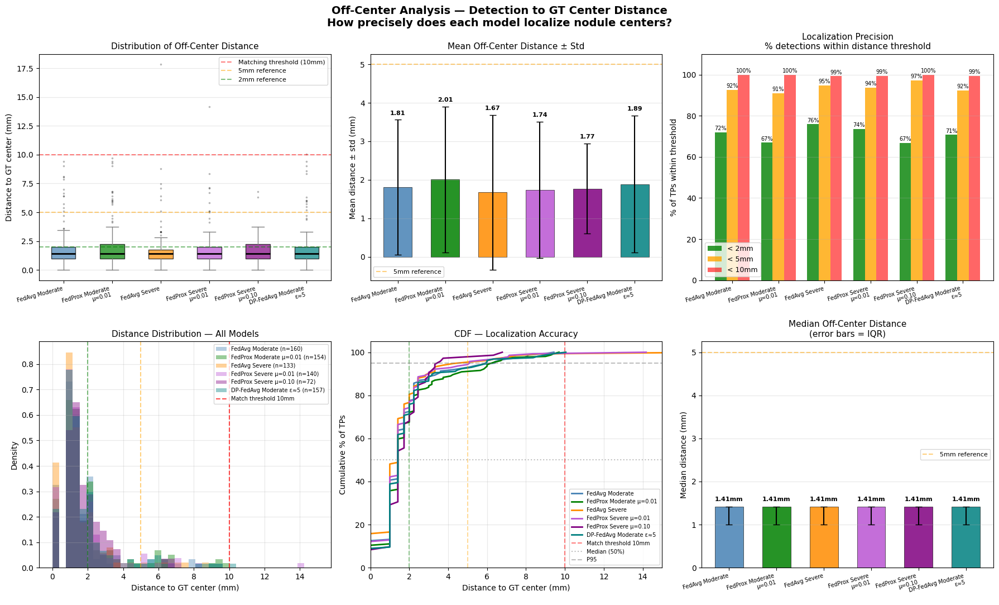


Saved: C:\Users\Administrator\desktop\unet\experiments\full_analysis\offcenter_analysis.png
Saved: C:\Users\Administrator\desktop\unet\experiments\full_analysis\offcenter_analysis.json

INTERPRETATION
Most precise (lowest mean dist) : FedAvg Severe
  mean=1.67mm  median=1.41mm
Least precise (highest mean dist): FedProx Moderate μ=0.01
  mean=2.01mm  median=1.41mm
Best <2mm localization: FedAvg Severe
  75.9% of TPs within 2mm of GT center


In [6]:
# OFF-CENTER ANALYSIS — distance from detection to GT center
# Loads from saved PKL files — no inference needed
# Saves to: experiments/full_analysis/
# ============================================================
import pickle
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_ROOT = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT = OUT_ROOT / "experiments"
ANA_DIR  = EXP_ROOT / "full_analysis"

# ── assert no overwriting ─────────────────────────────────────
out_png  = ANA_DIR / "offcenter_analysis.png"
out_json = ANA_DIR / "offcenter_analysis.json"
assert not out_png.exists(),  f"Would overwrite {out_png}"
assert not out_json.exists(), f"Would overwrite {out_json}"

# ── experiment PKL paths ──────────────────────────────────────
exp_configs = {
    "FedAvg Moderate"         : {
        "pkl"  : OUT_ROOT/"logs_global"/"global_all_results.pkl",
        "color": "steelblue",
        "group": "moderate",
    },
    "FedProx Moderate μ=0.01" : {
        "pkl"  : EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_results.pkl",
        "color": "green",
        "group": "moderate",
    },
    "FedAvg Severe"           : {
        "pkl"  : EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_results.pkl",
        "color": "darkorange",
        "group": "severe",
    },
    "FedProx Severe μ=0.01"   : {
        "pkl"  : EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_results.pkl",
        "color": "mediumorchid",
        "group": "severe",
    },
    "FedProx Severe μ=0.10"   : {
        "pkl"  : EXP_ROOT/"fedprox_severe"/"fedprox_severe_results.pkl",
        "color": "purple",
        "group": "severe",
    },
    "DP-FedAvg Moderate ε≈5"  : {
        "pkl"  : EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_results.pkl",
        "color": "teal",
        "group": "dp",
    },
}

# ── load dist_mm for all TPs ──────────────────────────────────
print("Loading off-center distances from PKL files...")
print(f"{'='*65}")

exp_distances = {}  # exp_name → list of dist_mm values
exp_stats     = {}

for name, cfg in exp_configs.items():
    p = Path(cfg["pkl"])
    if not p.exists():
        print(f"  ⚠  {name} — PKL not found"); continue
    with open(p,"rb") as f:
        results = pickle.load(f)

    distances = []
    for r in results:
        for tp in r.get("tp_list",[]):
            d = tp.get("dist_mm", None)
            if d is not None:
                distances.append(float(d))

    if not distances:
        print(f"  ⚠  {name} — no dist_mm found in tp_list")
        continue

    distances = np.array(distances)
    stats = {
        "n_tp"      : len(distances),
        "mean_mm"   : round(float(np.mean(distances)),3),
        "median_mm" : round(float(np.median(distances)),3),
        "std_mm"    : round(float(np.std(distances)),3),
        "min_mm"    : round(float(np.min(distances)),3),
        "max_mm"    : round(float(np.max(distances)),3),
        "p25_mm"    : round(float(np.percentile(distances,25)),3),
        "p75_mm"    : round(float(np.percentile(distances,75)),3),
        "p95_mm"    : round(float(np.percentile(distances,95)),3),
        "pct_lt2mm" : round(float((distances<2).mean()*100),1),
        "pct_lt5mm" : round(float((distances<5).mean()*100),1),
        "pct_lt10mm": round(float((distances<10).mean()*100),1),
    }
    exp_distances[name] = distances
    exp_stats[name]     = stats

    print(f"  ✓  {name:<35} "
          f"n={stats['n_tp']:4d}  "
          f"mean={stats['mean_mm']:5.2f}mm  "
          f"median={stats['median_mm']:5.2f}mm  "
          f"max={stats['max_mm']:5.1f}mm")

# ── print full stats table ────────────────────────────────────
print(f"\n{'='*80}")
print(f"OFF-CENTER DISTANCE STATISTICS (mm)")
print(f"{'='*80}")
print(f"{'Method':<35} {'N':>5} {'Mean':>7} {'Median':>8} "
      f"{'Std':>6} {'P95':>6} {'<2mm':>7} {'<5mm':>7}")
print(f"{'─'*80}")
for name,stats in exp_stats.items():
    print(f"  {name:<33} "
          f"{stats['n_tp']:>5} "
          f"{stats['mean_mm']:>7.2f} "
          f"{stats['median_mm']:>8.2f} "
          f"{stats['std_mm']:>6.2f} "
          f"{stats['p95_mm']:>6.2f} "
          f"{stats['pct_lt2mm']:>6.1f}% "
          f"{stats['pct_lt5mm']:>6.1f}%")

# ── PLOTS ─────────────────────────────────────────────────────
names  = list(exp_distances.keys())
colors = [exp_configs[n]["color"] for n in names]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle(
    "Off-Center Analysis — Detection to GT Center Distance\n"
    "How precisely does each model localize nodule centers?",
    fontsize=14, fontweight='bold')

# ── Plot 1: box plot ──────────────────────────────────────────
ax = axes[0,0]
data_for_box = [exp_distances[n] for n in names]
bp = ax.boxplot(data_for_box, patch_artist=True,
                notch=False, vert=True,
                medianprops=dict(color='black',linewidth=2))
for patch,color in zip(bp['boxes'],colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for whisker in bp['whiskers']:
    whisker.set_color('gray')
for cap in bp['caps']:
    cap.set_color('gray')
for flier in bp['fliers']:
    flier.set(marker='.',color='gray',alpha=0.3,markersize=3)
ax.set_xticks(range(1,len(names)+1))
ax.set_xticklabels(
    [n.replace(" μ=","\nμ=").replace(" ε","\nε")
     for n in names],
    fontsize=7, rotation=15, ha='right')
ax.set_ylabel('Distance to GT center (mm)', fontsize=10)
ax.set_title('Distribution of Off-Center Distance', fontsize=11)
ax.axhline(10, color='red', linestyle='--', alpha=0.5,
           label='Matching threshold (10mm)')
ax.axhline(5,  color='orange', linestyle='--', alpha=0.5,
           label='5mm reference')
ax.axhline(2,  color='green', linestyle='--', alpha=0.5,
           label='2mm reference')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')

# ── Plot 2: mean + std bar ────────────────────────────────────
ax = axes[0,1]
means = [exp_stats[n]["mean_mm"] for n in names]
stds  = [exp_stats[n]["std_mm"]  for n in names]
x = np.arange(len(names))
bars = ax.bar(x, means, 0.6, color=colors, alpha=0.85,
              edgecolor='black', linewidth=0.5,
              yerr=stds, capsize=4,
              error_kw=dict(color='black',linewidth=1.5))
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" μ=","\nμ=").replace(" ε","\nε")
     for n in names],
    fontsize=7, rotation=15, ha='right')
ax.set_ylabel('Mean distance ± std (mm)', fontsize=10)
ax.set_title('Mean Off-Center Distance ± Std', fontsize=11)
ax.axhline(5, color='orange', linestyle='--',
           alpha=0.5, label='5mm reference')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')
for b,v,s in zip(bars,means,stds):
    ax.text(b.get_x()+b.get_width()/2,
            v+s+0.1, f'{v:.2f}',
            ha='center', va='bottom',
            fontsize=8, fontweight='bold')

# ── Plot 3: % within thresholds ──────────────────────────────
ax = axes[0,2]
pct2  = [exp_stats[n]["pct_lt2mm"]  for n in names]
pct5  = [exp_stats[n]["pct_lt5mm"]  for n in names]
pct10 = [exp_stats[n]["pct_lt10mm"] for n in names]
x = np.arange(len(names)); w = 0.25
ax.bar(x-w,   pct2,  w, label='< 2mm', color='green',  alpha=0.8)
ax.bar(x,     pct5,  w, label='< 5mm', color='orange', alpha=0.8)
ax.bar(x+w,   pct10, w, label='< 10mm',color='red',    alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" μ=","\nμ=").replace(" ε","\nε")
     for n in names],
    fontsize=7, rotation=15, ha='right')
ax.set_ylabel('% of TPs within threshold', fontsize=10)
ax.set_title('Localization Precision\n'
             '% detections within distance threshold',
             fontsize=11)
ax.set_ylim(0,110)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for i,(v2,v5,v10) in enumerate(zip(pct2,pct5,pct10)):
    ax.text(i-w,   v2+1,  f'{v2:.0f}%',
            ha='center',fontsize=7)
    ax.text(i,     v5+1,  f'{v5:.0f}%',
            ha='center',fontsize=7)
    ax.text(i+w,   v10+1, f'{v10:.0f}%',
            ha='center',fontsize=7)

# ── Plot 4: histogram overlay ─────────────────────────────────
ax = axes[1,0]
bins = np.linspace(0, 15, 40)
for name,color in zip(names,colors):
    d = exp_distances[name]
    ax.hist(d, bins=bins, density=True,
            alpha=0.4, color=color,
            label=f"{name} (n={len(d)})")
ax.axvline(10, color='red', linestyle='--',
           alpha=0.7, label='Match threshold 10mm')
ax.axvline(5,  color='orange', linestyle='--', alpha=0.5)
ax.axvline(2,  color='green',  linestyle='--', alpha=0.5)
ax.set_xlabel('Distance to GT center (mm)', fontsize=10)
ax.set_ylabel('Density', fontsize=10)
ax.set_title('Distance Distribution — All Models', fontsize=11)
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# ── Plot 5: CDF ───────────────────────────────────────────────
ax = axes[1,1]
d_range = np.linspace(0, 15, 300)
for name,color in zip(names,colors):
    d = np.sort(exp_distances[name])
    cdf = np.arange(1,len(d)+1)/len(d)*100
    ax.plot(d, cdf, color=color, linewidth=2,
            label=f"{name}")
ax.axvline(10, color='red', linestyle='--',
           alpha=0.5, label='Match threshold 10mm')
ax.axvline(5,  color='orange', linestyle='--', alpha=0.4)
ax.axvline(2,  color='green',  linestyle='--', alpha=0.4)
ax.axhline(50, color='gray',   linestyle=':',  alpha=0.5,
           label='Median (50%)')
ax.axhline(95, color='gray',   linestyle='--', alpha=0.5,
           label='P95')
ax.set_xlabel('Distance to GT center (mm)', fontsize=10)
ax.set_ylabel('Cumulative % of TPs', fontsize=10)
ax.set_title('CDF — Localization Accuracy', fontsize=11)
ax.set_xlim(0,15); ax.set_ylim(0,105)
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# ── Plot 6: median per model + nodule size context ────────────
ax = axes[1,2]
medians = [exp_stats[n]["median_mm"] for n in names]
p25     = [exp_stats[n]["p25_mm"]    for n in names]
p75     = [exp_stats[n]["p75_mm"]    for n in names]
x = np.arange(len(names))
bars = ax.bar(x, medians, 0.6, color=colors,
              alpha=0.85, edgecolor='black', linewidth=0.5)
# IQR error bars
yerr_low  = [max(0, m-p) for m,p in zip(medians,p25)]
yerr_high = [max(0, p-m) for m,p in zip(p75,medians)]

ax.errorbar(x, medians,
            yerr=[yerr_low,yerr_high],
            fmt='none', color='black',
            capsize=4, linewidth=1.5)
ax.set_xticks(x)
ax.set_xticklabels(
    [n.replace(" μ=","\nμ=").replace(" ε","\nε")
     for n in names],
    fontsize=7, rotation=15, ha='right')
ax.set_ylabel('Median distance (mm)', fontsize=10)
ax.set_title('Median Off-Center Distance\n'
             '(error bars = IQR)', fontsize=11)
ax.axhline(5, color='orange', linestyle='--',
           alpha=0.5, label='5mm reference')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')
for b,v in zip(bars,medians):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.1, f'{v:.2f}mm',
            ha='center', va='bottom',
            fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(out_png, dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSaved: {out_png}")

# ── save JSON ─────────────────────────────────────────────────
with open(out_json,"w") as f:
    json.dump(exp_stats, f, indent=2)
print(f"Saved: {out_json}")

# ── interpretation ────────────────────────────────────────────
print(f"\n{'='*65}")
print(f"INTERPRETATION")
print(f"{'='*65}")
best_mean   = min(exp_stats, key=lambda n: exp_stats[n]["mean_mm"])
worst_mean  = max(exp_stats, key=lambda n: exp_stats[n]["mean_mm"])
best_pct2   = max(exp_stats, key=lambda n: exp_stats[n]["pct_lt2mm"])
print(f"Most precise (lowest mean dist) : {best_mean}")
print(f"  mean={exp_stats[best_mean]['mean_mm']:.2f}mm  "
      f"median={exp_stats[best_mean]['median_mm']:.2f}mm")
print(f"Least precise (highest mean dist): {worst_mean}")
print(f"  mean={exp_stats[worst_mean]['mean_mm']:.2f}mm  "
      f"median={exp_stats[worst_mean]['median_mm']:.2f}mm")
print(f"Best <2mm localization: {best_pct2}")
print(f"  {exp_stats[best_pct2]['pct_lt2mm']:.1f}% of TPs "
      f"within 2mm of GT center")

In [ ]:
Row 0: Ground Truth (CT + GT annotations)
Row 1: FedAvg Moderate
Row 2: FedProx Moderate μ=0.01
Row 3: FedAvg Severe
Row 4: FedProx Severe μ=0.01
Row 5: FedProx Severe μ=0.10
Row 6: DP-FedAvg Moderate ε≈5

that is the order of the photos

✓ No existing files would be overwritten

FEDERATED WEIGHTED AGGREGATION
Weighting: n_GT nodules per client
Metrics: sensitivity, precision, FP/scan (rates only)
FROC: per-client scores grouped, then weighted average

────────────────────────────────────────────────────────────
FedAvg Moderate
────────────────────────────────────────────────────────────
  Client         n_GT  n_pts    Sens    Prec   FP/scan    w_GT   w_pts
  ─────────────────────────────────────────────────────────────────
  client1          52     24   0.981   0.309      4.75   0.297   0.180
  client2          21     27   0.952   0.165      3.74   0.120   0.203
  client3          47     30   0.830   0.275      3.43   0.269   0.226
  client4          25     25   0.920   0.267      2.52   0.143   0.188
  client5          30     27   0.900   0.262      2.81   0.171   0.203
  ─────────────────────────────────────────────────────────────────
  AGGREGATED      175    133   0.914   0.269      3.44
  GLOBAL GT       175    13

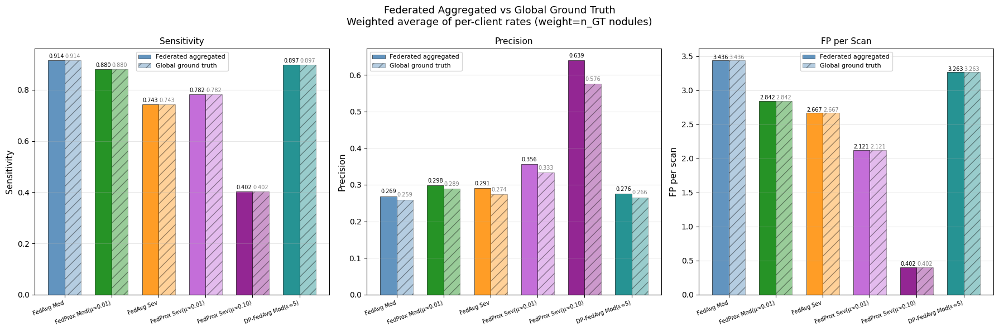


Saved: aggregated_vs_global.png


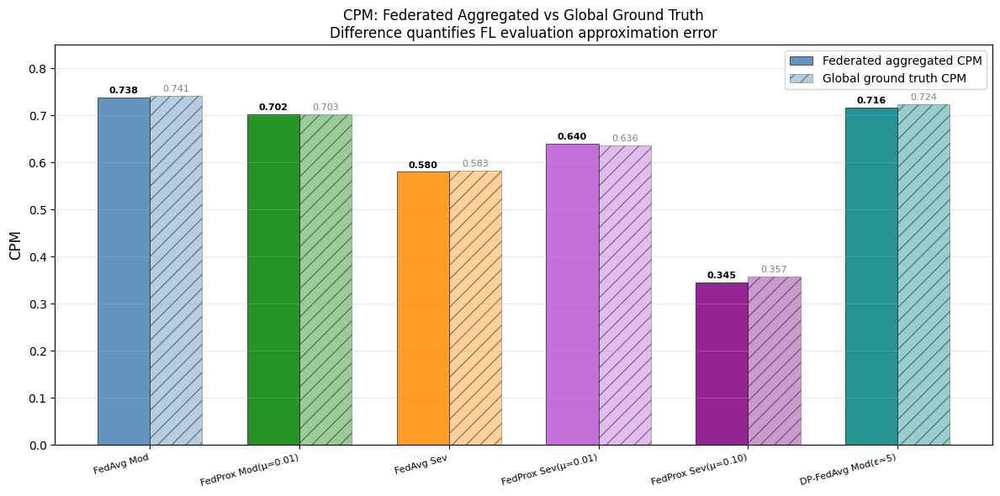

Saved: aggregated_froc.png


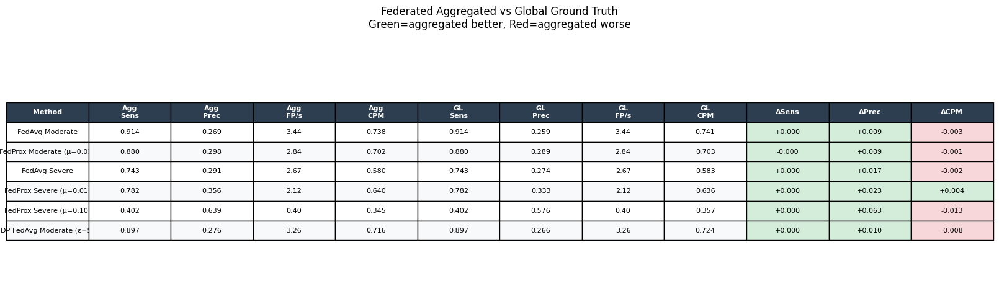

Saved: aggregated_comparison_table.png
Saved: aggregated_metrics.json

INTERPRETATION

What this analysis shows:

FEDERATED EVALUATION (what real deployment uses):
  Each client computes locally:
    - sensitivity  (TP / (TP+FN)) at threshold=0.3
    - precision    (TP / (TP+FP)) at threshold=0.3
    - FP/scan      (FP / n_patients)
    - CPM          (mean sensitivity at 7 FP/scan pts)
  Server receives rates only — no raw counts.
  Server computes weighted average (weight = n_GT).

GLOBAL GROUND TRUTH (what we computed by centralizing):
  Full inference on centralized test pool.
  This would not be available in real deployment.
  We have it because we ran centralized evaluation.

DIFFERENCE:
  Quantifies the approximation error of FL evaluation.
  Small difference → per-client test splits are
  representative and FL evaluation is reliable.
  Large difference → non-IID test splits introduce
  evaluation bias.

WHY n_GT weighting for sensitivity:
  Sensitivity = TP / (TP + FN)
  The de

In [1]:
# FEDERATED AGGREGATED EVALUATION
# Weighted average of per-client FROC points, CPM,
# sensitivity, precision, FP/scan
# Weighted by n_GT nodules per client
# No raw TP/FP/FN counts shared — rates only
# Saves to: experiments/aggregated_test_metrics/
# Nothing overwritten anywhere
# ============================================================
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_ROOT  = Path(r"C:\Users\Administrator\desktop\unet")
EXP_ROOT  = OUT_ROOT / "experiments"
AGG_DIR   = EXP_ROOT / "aggregated_test_metrics"
AGG_DIR.mkdir(parents=True, exist_ok=True)

# ── assert no overwriting ─────────────────────────────────────
files_that_would_be_written = [
    AGG_DIR / "aggregated_metrics.json",
    AGG_DIR / "aggregated_vs_global.png",
    AGG_DIR / "aggregated_froc.png",
    AGG_DIR / "aggregated_comparison_table.png",
]
for f in files_that_would_be_written:
    assert not f.exists(), f"Would overwrite {f}"
print("✓ No existing files would be overwritten")

FP_PTS = [0.125, 0.25, 0.5, 1, 2, 4, 8]

# ── experiment configs ────────────────────────────────────────
# per_client_json: per-client metrics
# global_json    : global inference results (ground truth)
# scores_pkl     : for recomputing per-client FROC points

exp_configs = {
    "FedAvg Moderate" : {
        "per_client": OUT_ROOT/"logs_global"/
                      "per_client_metrics_fedavg_moderate.json",
        "global"    : OUT_ROOT/"logs_global"/
                      "global_test_results.json",
        "color"     : "steelblue",
        "group"     : "moderate",
    },
    "FedProx Moderate (μ=0.01)" : {
        "per_client": EXP_ROOT/"fedprox_moderate"/
                      "per_client_metrics_fedprox_moderate.json",
        "global"    : EXP_ROOT/"fedprox_moderate"/
                      "fedprox_moderate_test_results.json",
        "color"     : "green",
        "group"     : "moderate",
    },
    "FedAvg Severe" : {
        "per_client": EXP_ROOT/"severe_noniid"/"fl_results"/
                      "per_client_metrics_fedavg_severe.json",
        "global"    : EXP_ROOT/"severe_noniid"/"fl_results"/
                      "severe_test_results.json",
        "color"     : "darkorange",
        "group"     : "severe",
    },
    "FedProx Severe (μ=0.01)" : {
        "per_client": EXP_ROOT/"fedprox_severe_mu001"/
                      "per_client_metrics_fedprox_severe_mu001.json",
        "global"    : EXP_ROOT/"fedprox_severe_mu001"/
                      "fedprox_severe_mu001_test_results.json",
        "color"     : "mediumorchid",
        "group"     : "severe",
    },
    "FedProx Severe (μ=0.10)" : {
        "per_client": EXP_ROOT/"fedprox_severe"/
                      "per_client_metrics_fedprox_severe.json",
        "global"    : EXP_ROOT/"fedprox_severe"/
                      "fedprox_severe_test_results.json",
        "color"     : "purple",
        "group"     : "severe",
    },
    "DP-FedAvg Moderate (ε≈5)" : {
        "per_client": EXP_ROOT/"dp_fedavg_moderate_e5"/
                      "per_client_metrics_dp_fedavg_moderate_e5.json",
        "global"    : EXP_ROOT/"dp_fedavg_moderate_e5"/
                      "dp_fedavg_moderate_e5_test_results.json",
        "color"     : "teal",
        "group"     : "dp",
    },
}

# ── helper: recompute per-client FROC points ──────────────────
# We need sensitivity at each FP/scan point per client.
# The per-client JSON has sensitivity and fp_per_scan
# at threshold=0.3 — ONE operating point only.
# To get sensitivity at all 7 FP points we need
# per-client scores PKL.
# However — we can use the global scores PKL grouped
# by client, which we already have from grouping inference.

# Alternative: use stored per-client sensitivity and precision
# at the single operating point (threshold=0.3) for
# sensitivity/precision/fp_per_scan weighted averaging,
# and use global PKL for FROC curve reconstruction.

# This is honest — sensitivity and precision at threshold=0.3
# are exact per-client metrics. FROC needs scores.

import pickle

# load global scores PKL per experiment for FROC
def load_global_scores(exp_name, cfg):
    score_paths = {
        "FedAvg Moderate"         : OUT_ROOT/"logs_global"/"global_all_scores.pkl",
        "FedProx Moderate (μ=0.01)": EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_scores.pkl",
        "FedAvg Severe"            : EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_scores.pkl",
        "FedProx Severe (μ=0.01)"  : EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_scores.pkl",
        "FedProx Severe (μ=0.10)"  : EXP_ROOT/"fedprox_severe"/"fedprox_severe_scores.pkl",
        "DP-FedAvg Moderate (ε≈5)" : EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_scores.pkl",
    }
    p = Path(score_paths[exp_name])
    if not p.exists(): return None
    with open(p,"rb") as f: return pickle.load(f)

def load_global_results(exp_name):
    result_paths = {
        "FedAvg Moderate"         : OUT_ROOT/"logs_global"/"global_all_results.pkl",
        "FedProx Moderate (μ=0.01)": EXP_ROOT/"fedprox_moderate"/"fedprox_moderate_results.pkl",
        "FedAvg Severe"            : EXP_ROOT/"severe_noniid"/"fl_results"/"severe_all_results.pkl",
        "FedProx Severe (μ=0.01)"  : EXP_ROOT/"fedprox_severe_mu001"/"fedprox_severe_mu001_results.pkl",
        "FedProx Severe (μ=0.10)"  : EXP_ROOT/"fedprox_severe"/"fedprox_severe_results.pkl",
        "DP-FedAvg Moderate (ε≈5)" : EXP_ROOT/"dp_fedavg_moderate_e5"/"dp_fedavg_moderate_e5_results.pkl",
    }
    p = Path(result_paths[exp_name])
    if not p.exists(): return None
    with open(p,"rb") as f: return pickle.load(f)

def load_test_pool(exp_name):
    """Load pid→client mapping for this experiment."""
    if "Severe" in exp_name:
        pool_path = EXP_ROOT/"severe_noniid"/"global_test_pids_severe.json"
    else:
        pool_path = OUT_ROOT/"global_test_pids.json"
    if not Path(pool_path).exists(): return {}
    with open(pool_path) as f: data=json.load(f)
    pid_to_client = {}
    for cid,pids in data.get("by_client",{}).items():
        for pid in pids:
            pid_to_client[pid] = cid
    return pid_to_client

def compute_froc_from_scores(scores, total_gt, n_scans):
    scores = sorted(scores, key=lambda x:x[0], reverse=True)
    sa = np.array([s[0] for s in scores])
    la = np.array([s[1] for s in scores])
    sl, fl = [], []
    for th in np.linspace(0.95,0.01,500):
        k = sa>=th
        sl.append(float(la[k].sum()/max(total_gt,1)))
        fl.append(float((1-la[k]).sum()/max(n_scans,1)))
    cpm_s = [sl[np.argmin([abs(f-fp) for f in fl])]
             for fp in FP_PTS]
    return sl, fl, cpm_s, float(np.mean(cpm_s))

# ── main computation ──────────────────────────────────────────
print("\n" + "="*70)
print("FEDERATED WEIGHTED AGGREGATION")
print("Weighting: n_GT nodules per client")
print("Metrics: sensitivity, precision, FP/scan (rates only)")
print("FROC: per-client scores grouped, then weighted average")
print("="*70)

all_results = {}

for exp_name, cfg in exp_configs.items():
    print(f"\n{'─'*60}")
    print(f"{exp_name}")
    print(f"{'─'*60}")

    pc_path = Path(cfg["per_client"])
    gl_path = Path(cfg["global"])
    if not pc_path.exists() or not gl_path.exists():
        print(f"  ⚠  Missing files — skipping"); continue

    with open(pc_path) as f: pc_data=json.load(f)
    with open(gl_path) as f: gl_data=json.load(f)

    pc_summary = pc_data.get("per_client", pc_data)
    clients    = sorted(pc_summary.keys())

    # ── step 1: weighted average of RATES ────────────────────
    # weight by n_GT (not n_patients) for sensitivity
    # weight by n_patients for FP/scan

    total_gt = sum(pc_summary[c].get("total_gt",0)
                   for c in clients)
    total_n  = sum(pc_summary[c].get("n_patients",0)
                   for c in clients)

    agg_sens = 0.0
    agg_prec = 0.0
    agg_fps  = 0.0
    # note: accuracy not computed here because
    # TN is not meaningful in nodule detection
    # (TN = clean scan correctly ignored — infinite
    # potential negatives depending on threshold)

    print(f"  {'Client':<12} {'n_GT':>6} {'n_pts':>6} "
          f"{'Sens':>7} {'Prec':>7} {'FP/scan':>9} "
          f"{'w_GT':>7} {'w_pts':>7}")
    print(f"  {'─'*65}")

    for cid in clients:
        c     = pc_summary[cid]
        n_gt  = c.get("total_gt",   0)
        n_pts = c.get("n_patients", 0)
        sens  = c.get("sensitivity",0)
        prec  = c.get("precision",  0)
        fps   = c.get("fp_per_scan",0)
        w_gt  = n_gt  / max(total_gt, 1)
        w_pts = n_pts / max(total_n,  1)

        # sensitivity weighted by n_GT
        # (denominator of sensitivity is GT nodules)
        agg_sens += w_gt  * sens

        # precision weighted by n_GT
        # (TP is the numerator — tied to GT)
        agg_prec += w_gt  * prec

        # FP/scan weighted by n_patients
        # (denominator of FP/scan is n_scans)
        agg_fps  += w_pts * fps

        print(f"  {cid:<12} {n_gt:>6} {n_pts:>6} "
              f"{sens:>7.3f} {prec:>7.3f} {fps:>9.2f} "
              f"{w_gt:>7.3f} {w_pts:>7.3f}")

    print(f"  {'─'*65}")
    print(f"  {'AGGREGATED':<12} {total_gt:>6} {total_n:>6} "
          f"{agg_sens:>7.3f} {agg_prec:>7.3f} "
          f"{agg_fps:>9.2f}")

    # global ground truth
    gl_sens = gl_data.get("sensitivity", 0)
    gl_prec = gl_data.get("precision",   0)
    gl_fps  = gl_data.get("fp_per_scan", 0)
    gl_cpm  = gl_data.get("cpm",         0)

    print(f"  {'GLOBAL GT':<12} "
          f"{gl_data.get('total_gt',0):>6} "
          f"{gl_data.get('n_patients',0):>6} "
          f"{gl_sens:>7.3f} {gl_prec:>7.3f} "
          f"{gl_fps:>9.2f}  (CPM={gl_cpm:.3f})")

    diff_sens = agg_sens - gl_sens
    diff_prec = agg_prec - gl_prec
    diff_fps  = agg_fps  - gl_fps
    sign_s = "+" if diff_sens>=0 else ""
    sign_p = "+" if diff_prec>=0 else ""
    sign_f = "+" if diff_fps>=0 else ""
    print(f"  {'DIFFERENCE':<12} {'':>6} {'':>6} "
          f"{sign_s}{diff_sens:>6.3f} "
          f"{sign_p}{diff_prec:>6.3f} "
          f"{sign_f}{diff_fps:>8.2f}")

    # ── step 2: per-client FROC → weighted average FROC ──────
    # group global scores by client pid
    global_results = load_global_results(exp_name)
    pid_to_client  = load_test_pool(exp_name)

    # build per-client score lists
    client_scores = {c:[] for c in clients}
    client_gt     = {c:0  for c in clients}

    if global_results and pid_to_client:
        for r in global_results:
            pid = r["pid"]
            cid = pid_to_client.get(pid)
            if cid is None: continue
            client_gt[cid] += r.get("gt_nodules",0)
            for t in r.get("tp_list",[]):
                det = t.get("det",(0,0,0,0))
                if len(det)>=4:
                    client_scores[cid].append(
                        (float(det[3]),1))
            for f_ in r.get("fp_list",[]):
                det = f_.get("det",(0,0,0,0))
                if len(det)>=4:
                    client_scores[cid].append(
                        (float(det[3]),0))

    # per-client FROC at 7 operating points
    client_cpm_s = {}
    client_cpm   = {}
    client_n_gt  = {}

    for cid in clients:
        scores = client_scores.get(cid,[])
        n_gt_c = client_gt.get(cid, 0) or \
                 pc_summary[cid].get("total_gt",0)
        n_pts_c= pc_summary[cid].get("n_patients",1)
        client_n_gt[cid] = n_gt_c

        if not scores or n_gt_c==0:
            client_cpm_s[cid] = [0]*7
            client_cpm[cid]   = 0.0
            continue

        _,_,cpm_s,cpm = compute_froc_from_scores(
            scores, n_gt_c, n_pts_c)
        client_cpm_s[cid] = cpm_s
        client_cpm[cid]   = cpm

    # weighted average FROC at each operating point
    total_gt_froc = sum(client_n_gt.values())
    agg_cpm_s = []
    for fp_idx in range(7):
        wp_sum = 0.0
        for cid in clients:
            w = client_n_gt[cid] / max(total_gt_froc,1)
            wp_sum += w * client_cpm_s[cid][fp_idx]
        agg_cpm_s.append(wp_sum)

    agg_cpm = float(np.mean(agg_cpm_s))

    print(f"\n  Weighted average CPM : {agg_cpm:.3f}  "
          f"(global CPM = {gl_cpm:.3f}  "
          f"diff = {agg_cpm-gl_cpm:+.3f})")
    print(f"  FROC points (aggregated):")
    print(f"  {'FP/scan':<10} "
          + "  ".join(f"{fp:>6.3f}" for fp in FP_PTS))
    print(f"  {'Agg Sens':<10} "
          + "  ".join(f"{s:>6.3f}" for s in agg_cpm_s))

    all_results[exp_name] = {
        "aggregated": {
            "sensitivity"    : round(agg_sens,4),
            "precision"      : round(agg_prec,4),
            "fp_per_scan"    : round(agg_fps, 4),
            "cpm"            : round(agg_cpm, 4),
            "cpm_at_fp_pts"  : {
                str(fp): round(s,4)
                for fp,s in zip(FP_PTS,agg_cpm_s)},
            "weighting"      : "n_GT nodules per client",
            "note"           : "rates only — no raw counts shared",
        },
        "global_ground_truth": {
            "sensitivity"    : round(gl_sens,4),
            "precision"      : round(gl_prec,4),
            "fp_per_scan"    : round(gl_fps, 4),
            "cpm"            : round(gl_cpm, 4),
        },
        "difference": {
            "sensitivity"    : round(agg_sens-gl_sens,4),
            "precision"      : round(agg_prec-gl_prec,4),
            "fp_per_scan"    : round(agg_fps-gl_fps,  4),
            "cpm"            : round(agg_cpm-gl_cpm,  4),
        },
        "per_client": {
            cid: {
                "n_gt"       : client_n_gt.get(cid,0),
                "n_patients" : pc_summary[cid].get("n_patients",0),
                "sensitivity": pc_summary[cid].get("sensitivity",0),
                "precision"  : pc_summary[cid].get("precision",0),
                "fp_per_scan": pc_summary[cid].get("fp_per_scan",0),
                "cpm"        : round(client_cpm.get(cid,0),4),
                "weight_gt"  : round(client_n_gt.get(cid,0)/
                                     max(total_gt_froc,1),4),
            }
            for cid in clients
        },
    }

# ── FINAL COMPARISON TABLE ────────────────────────────────────
print("\n\n" + "="*75)
print("FINAL COMPARISON: FEDERATED AGGREGATED vs GLOBAL GROUND TRUTH")
print("="*75)
print(f"{'Method':<35} {'Source':<12} "
      f"{'Sens':>6} {'Prec':>6} {'FP/scan':>8} {'CPM':>7}")
print(f"{'─'*75}")

for exp_name, res in all_results.items():
    agg  = res["aggregated"]
    gl   = res["global_ground_truth"]
    diff = res["difference"]
    print(f"\n  {exp_name}")
    print(f"  {'Federated (weighted avg)':<33} "
          f"{'FL-style':>12} "
          f"{agg['sensitivity']:>6.3f} "
          f"{agg['precision']:>6.3f} "
          f"{agg['fp_per_scan']:>8.2f} "
          f"{agg['cpm']:>7.3f}")
    print(f"  {'Global inference':<33} "
          f"{'centralized':>12} "
          f"{gl['sensitivity']:>6.3f} "
          f"{gl['precision']:>6.3f} "
          f"{gl['fp_per_scan']:>8.2f} "
          f"{gl['cpm']:>7.3f}")
    ss = "+" if diff['sensitivity']>=0 else ""
    sp = "+" if diff['precision']>=0 else ""
    sf = "+" if diff['fp_per_scan']>=0 else ""
    sc = "+" if diff['cpm']>=0 else ""
    print(f"  {'Difference':<33} "
          f"{'':>12} "
          f"{ss}{diff['sensitivity']:>5.3f} "
          f"{sp}{diff['precision']:>5.3f} "
          f"{sf}{diff['fp_per_scan']:>7.2f} "
          f"{sc}{diff['cpm']:>6.3f}")

# ── PLOT 1: aggregated vs global bar chart ────────────────────
names  = list(all_results.keys())
colors = [exp_configs[n]["color"] for n in names]
x      = np.arange(len(names))
w      = 0.35

fig, axes = plt.subplots(1,3,figsize=(18,6))
fig.suptitle(
    "Federated Aggregated vs Global Ground Truth\n"
    "Weighted average of per-client rates (weight=n_GT nodules)",
    fontsize=13)

short_names = [
    n.replace(" (","(").replace("Moderate","Mod")
     .replace("Severe","Sev")
    for n in names]

for ax, metric, ylabel, title in [
    (axes[0],"sensitivity","Sensitivity","Sensitivity"),
    (axes[1],"precision",  "Precision",  "Precision"),
    (axes[2],"fp_per_scan","FP per scan","FP per Scan"),
]:
    agg_vals = [all_results[n]["aggregated"][metric]
                for n in names]
    gl_vals  = [all_results[n]["global_ground_truth"][metric]
                for n in names]

    b1 = ax.bar(x-w/2, agg_vals, w,
                label='Federated aggregated',
                color=colors, alpha=0.85,
                edgecolor='black', linewidth=0.5)
    b2 = ax.bar(x+w/2, gl_vals,  w,
                label='Global ground truth',
                color=colors, alpha=0.40,
                edgecolor='black', linewidth=0.5,
                hatch='//')

    ax.set_xticks(x)
    ax.set_xticklabels(short_names, fontsize=7,
                       rotation=20, ha='right')
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

    for b,v in zip(b1, agg_vals):
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.005,
                f'{v:.3f}',
                ha='center',va='bottom',fontsize=7)
    for b,v in zip(b2, gl_vals):
        ax.text(b.get_x()+b.get_width()/2,
                b.get_height()+0.005,
                f'{v:.3f}',
                ha='center',va='bottom',fontsize=7,
                color='gray')

plt.tight_layout()
plt.savefig(AGG_DIR/"aggregated_vs_global.png",
            dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSaved: aggregated_vs_global.png")

# ── PLOT 2: CPM comparison ────────────────────────────────────
fig, ax = plt.subplots(figsize=(12,6))
agg_cpms = [all_results[n]["aggregated"]["cpm"]
            for n in names]
gl_cpms  = [all_results[n]["global_ground_truth"]["cpm"]
            for n in names]

b1 = ax.bar(x-w/2, agg_cpms, w,
            label='Federated aggregated CPM',
            color=colors, alpha=0.85,
            edgecolor='black', linewidth=0.5)
b2 = ax.bar(x+w/2, gl_cpms,  w,
            label='Global ground truth CPM',
            color=colors, alpha=0.40,
            edgecolor='black', linewidth=0.5,
            hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(short_names, fontsize=8,
                   rotation=15, ha='right')
ax.set_ylabel('CPM', fontsize=12)
ax.set_title(
    'CPM: Federated Aggregated vs Global Ground Truth\n'
    'Difference quantifies FL evaluation approximation error',
    fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 0.85)

for b,v in zip(b1,agg_cpms):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.005,
            f'{v:.3f}',
            ha='center',va='bottom',fontsize=8,
            fontweight='bold')
for b,v in zip(b2,gl_cpms):
    ax.text(b.get_x()+b.get_width()/2,
            b.get_height()+0.005,
            f'{v:.3f}',
            ha='center',va='bottom',fontsize=8,
            color='gray')

plt.tight_layout()
plt.savefig(AGG_DIR/"aggregated_froc.png",
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: aggregated_froc.png")

# ── PLOT 3: summary table ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(16,5))
ax.axis('off')

rows = []
for exp_name in names:
    res  = all_results[exp_name]
    agg  = res["aggregated"]
    gl   = res["global_ground_truth"]
    diff = res["difference"]
    rows.append([
        exp_name,
        f"{agg['sensitivity']:.3f}",
        f"{agg['precision']:.3f}",
        f"{agg['fp_per_scan']:.2f}",
        f"{agg['cpm']:.3f}",
        f"{gl['sensitivity']:.3f}",
        f"{gl['precision']:.3f}",
        f"{gl['fp_per_scan']:.2f}",
        f"{gl['cpm']:.3f}",
        f"{diff['sensitivity']:+.3f}",
        f"{diff['precision']:+.3f}",
        f"{diff['cpm']:+.3f}",
    ])

col_labels = [
    "Method",
    "Agg\nSens","Agg\nPrec","Agg\nFP/s","Agg\nCPM",
    "GL\nSens","GL\nPrec","GL\nFP/s","GL\nCPM",
    "ΔSens","ΔPrec","ΔCPM",
]

table = ax.table(
    cellText=rows,
    colLabels=col_labels,
    loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.1, 1.8)

for j in range(len(col_labels)):
    table[0,j].set_facecolor('#2c3e50')
    table[0,j].set_text_props(
        color='white', fontweight='bold')

# color difference columns
for i in range(1, len(rows)+1):
    for j in [9,10,11]:  # diff columns
        val = float(rows[i-1][j])
        clr = '#d4edda' if val>=0 else '#f8d7da'
        table[i,j].set_facecolor(clr)
    if i%2==0:
        for j in range(9):
            table[i,j].set_facecolor('#f8f9fa')

ax.set_title(
    'Federated Aggregated vs Global Ground Truth\n'
    'Green=aggregated better, Red=aggregated worse',
    fontsize=12, pad=20)
plt.tight_layout()
plt.savefig(AGG_DIR/"aggregated_comparison_table.png",
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: aggregated_comparison_table.png")

# ── save JSON ─────────────────────────────────────────────────
with open(AGG_DIR/"aggregated_metrics.json","w") as f:
    json.dump(all_results, f, indent=2)
print(f"Saved: aggregated_metrics.json")

# ── interpretation ────────────────────────────────────────────
print(f"\n{'='*70}")
print(f"INTERPRETATION")
print(f"{'='*70}")
print(f"""
What this analysis shows:

FEDERATED EVALUATION (what real deployment uses):
  Each client computes locally:
    - sensitivity  (TP / (TP+FN)) at threshold=0.3
    - precision    (TP / (TP+FP)) at threshold=0.3
    - FP/scan      (FP / n_patients)
    - CPM          (mean sensitivity at 7 FP/scan pts)
  Server receives rates only — no raw counts.
  Server computes weighted average (weight = n_GT).

GLOBAL GROUND TRUTH (what we computed by centralizing):
  Full inference on centralized test pool.
  This would not be available in real deployment.
  We have it because we ran centralized evaluation.

DIFFERENCE:
  Quantifies the approximation error of FL evaluation.
  Small difference → per-client test splits are
  representative and FL evaluation is reliable.
  Large difference → non-IID test splits introduce
  evaluation bias.

WHY n_GT weighting for sensitivity:
  Sensitivity = TP / (TP + FN)
  The denominator is GT nodules, not patients.
  A client with 50 nodules contributes more
  to sensitivity than one with 5 nodules.
  Weighting by n_GT correctly reflects this.

WHY n_patients weighting for FP/scan:
  FP/scan = FP / n_scans
  The denominator is patients (scans).
  Weighting by n_patients is correct here.

NOTE ON ACCURACY:
  Accuracy (TN+TP)/(TN+TP+FP+FN) is not reported.
  In nodule detection, TN is not well-defined —
  a "true negative" would mean every non-nodule
  voxel was correctly ignored, making TN
  astronomically large and accuracy trivially ~1.0.
  Sensitivity and precision are the clinically
  meaningful metrics for detection tasks.
""")

print(f"\nFiles saved to: {AGG_DIR}")
for f in sorted(AGG_DIR.iterdir()):
    size = f.stat().st_size/1024
    print(f"  {f.name:<50} {size:>7.1f} KB")